# TP – LeNet-5 sur la base AMHCD (caractères Tifinagh)
**Masters IMSD & IAA – CNN LeNet-5**

**Réalisé par : Sohayeb Gasmi**


**Encadré par : Dr.M. BENADDY ET Dr.A. HADRI**



Lien Github : https://github.com/SohayebGasmi-IA79/LeNet5_Tifinagh_CNN


Contenu du notebook :
1. Configuration et chargement des données (détection automatique du dossier)
2. Exploration (distribution des classes, exemples)
3. Couches paramétrables + architecture LeNet-5 (32×32×1, 33 classes)
4. Optimiseurs implémentés à la main (SGD, SGD+Momentum, RMSprop, Adam)
5. Fonctions d'apprentissage (train / validation / test)
6. Courbes loss/accuracy, matrice de confusion, cartes caractéristiques, filtres, erreurs, etc.
7. comparison : comparaison de 11 optimiseurs
8. les algorithmes : améliorations (augmentation, ReLU, MaxPool, BatchNorm, Dropout, label smoothing, AdamW, OneCycle, LeNet5Plus) avec étude d'ablation, ensemble + TTA, test de McNemar, Grad-CAM

## 1. Imports et configuration

In [ ]:
import os, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

# ----------------- PARAMETRES (modifiables) -----------------
SEED       = 42
IMG_SIZE   = 32      # LeNet-5 : 32x32 (ne pas changer)
CHANNELS   = 1       # 1 = niveaux de gris (énoncé du PDF) ; 3 = RGB (énoncé Classroom)
BATCH_SIZE = 128
EPOCHS     = 30
LR         = 1e-3
OPTIMIZER  = 'adam'  # voir ALL_OPTIMIZERS plus bas (sgd, sgd_momentum, nesterov, adagrad, adadelta, rmsprop, adam, adamw, amsgrad, nadam, adamax)
ACTIVATION = 'tanh'  # 'tanh' | 'relu' | 'sigmoid' | 'leaky_relu'
DATA_DIR   = None    # mettre le chemin du dataset si la détection automatique échoue
OUT_DIR    = 'outputs'
# -------------------------------------------------------------
os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()
plt.rcParams['figure.dpi'] = 110
print('Device :', DEVICE, '| torch', torch.__version__)

Device : cuda | torch 2.14.0+cu130


## 2. Chargement de la base AMHCD

In [ ]:
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

def count_images(folder):
    return sum(1 for _, _, fs in os.walk(folder) for f in fs if f.lower().endswith(IMG_EXT))

def find_data_root():
    cands = [DATA_DIR] if DATA_DIR else []
    cands += ['/kaggle/input/amazigh-handwritten-character-database-amhcd', '/kaggle/input',
              './data', '/content', '.']
    for c in cands:
        if c and os.path.isdir(c) and count_images(c) > 1000:
            return c
    # Dernier recours : téléchargement via kagglehub (Colab / machine avec internet + compte Kaggle)
    try:
        import kagglehub
        return kagglehub.dataset_download('benaddym/amazigh-handwritten-character-database-amhcd')
    except Exception as e:
        raise RuntimeError("Dataset introuvable. Renseignez DATA_DIR avec le dossier contenant les images. "
                           f"Détail : {e}")

ROOT = find_data_root()
print('Dossier des données :', ROOT)

paths, labels = [], []
for dp, _, fs in os.walk(ROOT):
    for f in fs:
        if f.lower().endswith(IMG_EXT):
            paths.append(os.path.join(dp, f))
            labels.append(os.path.basename(dp))

# Si la structure est classe/<sous-dossier>/img, on remonte d'un niveau
if len(set(labels)) < 20:
    labels = [os.path.basename(os.path.dirname(os.path.dirname(p))) for p in paths]

class_names = sorted(set(labels), key=lambda s: (len(s), s))
class_to_idx = {c: i for i, c in enumerate(class_names)}
y_all = np.array([class_to_idx[l] for l in labels], dtype=np.int64)
NUM_CLASSES = len(class_names)
print(f'{len(paths)} images | {NUM_CLASSES} classes')
if NUM_CLASSES != 33:
    print('ATTENTION : 33 classes attendues. Vérifiez DATA_DIR / la structure des dossiers.')
print(class_names)

Dossier des données : /home/gotrinx/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1
51480 images | 33 classes
['ya', 'yi', 'yu', 'yab', 'yad', 'yae', 'yaf', 'yag', 'yah', 'yaj', 'yak', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yas', 'yat', 'yaw', 'yax', 'yay', 'yaz', 'yey', 'yach', 'yadd', 'yagh', 'yagw', 'yahh', 'yakw', 'yarr', 'yass', 'yatt', 'yazz']


In [ ]:
def load_img(p):
    im = Image.open(p).convert('L' if CHANNELS == 1 else 'RGB')
    im = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

X_all = np.stack([load_img(p) for p in tqdm(paths, desc='Chargement')])
X_all = X_all[:, None, :, :] if CHANNELS == 1 else X_all.transpose(0, 3, 1, 2)   # (N, C, H, W)
print('X :', X_all.shape, X_all.dtype, '| y :', y_all.shape)

Chargement:   0%|          | 0/51480 [00:00<?, ?it/s]

X : (51480, 1, 32, 32) uint8 | y : (51480,)


### Découpage train / validation / test (70 / 15 / 15, stratifié) et normalisation

In [ ]:
idx = np.arange(len(X_all))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=SEED)
print('train / val / test :', len(tr_idx), len(va_idx), len(te_idx))

Xf = X_all.astype(np.float32) / 255.0
MEAN = Xf[tr_idx].mean(axis=(0, 2, 3), keepdims=True)     # statistiques calculées sur le train uniquement
STD  = Xf[tr_idx].std(axis=(0, 2, 3), keepdims=True) + 1e-8
Xn = (Xf - MEAN) / STD

def make_loader(ids, shuffle):
    ds = TensorDataset(torch.from_numpy(Xn[ids]), torch.from_numpy(y_all[ids]))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      pin_memory=(DEVICE.type == 'cuda'))

train_loader = make_loader(tr_idx, True)
val_loader   = make_loader(va_idx, False)
test_loader  = make_loader(te_idx, False)

def denorm(x):  # tenseur/array normalisé (C,H,W) -> image affichable
    x = np.asarray(x) * STD[0] + MEAN[0]
    x = np.clip(x, 0, 1)
    return x[0] if x.shape[0] == 1 else x.transpose(1, 2, 0)

train / val / test : 36036 7722 7722


## 3. Exploration des données

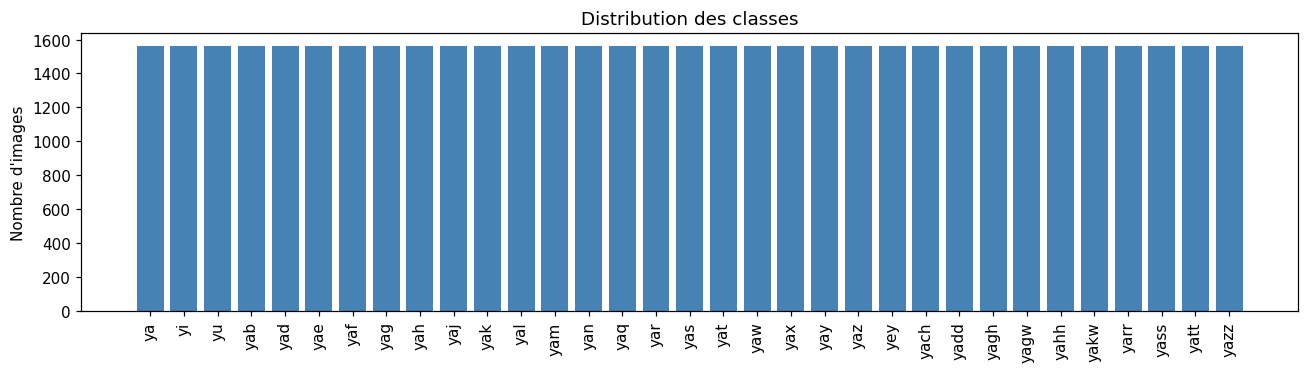

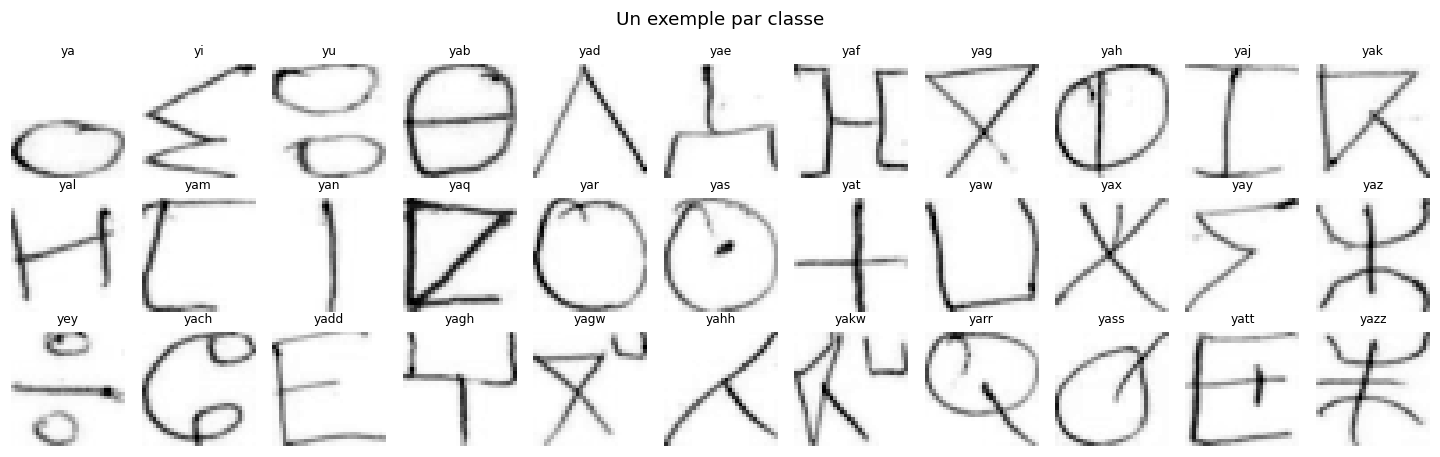

In [ ]:
# Distribution des classes
counts = np.bincount(y_all, minlength=NUM_CLASSES)
plt.figure(figsize=(12, 3.5))
plt.bar(range(NUM_CLASSES), counts, color='steelblue')
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.title('Distribution des classes'); plt.ylabel("Nombre d'images"); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/class_distribution.png'); plt.show()

# Un exemple par classe
cols = 11; rows = int(np.ceil(NUM_CLASSES / cols))
fig, axs = plt.subplots(rows, cols, figsize=(cols * 1.2, rows * 1.4))
for k, ax in enumerate(np.array(axs).ravel()):
    ax.axis('off')
    if k < NUM_CLASSES:
        i = np.where(y_all == k)[0][0]
        ax.imshow(denorm(Xn[i]), cmap='gray'); ax.set_title(class_names[k], fontsize=8)
plt.suptitle('Un exemple par classe'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/samples.png'); plt.show()

## 4. Architecture LeNet-5 – couches paramétrables

| Couche | Opération | Sortie |
|---|---|---|
| Entrée | image | 1×32×32 |
| C1 | Conv 5×5, 6 filtres | 6×28×28 |
| S2 | Pooling moyen 2×2, stride 2 | 6×14×14 |
| C3 | Conv 5×5, 16 filtres | 16×10×10 |
| S4 | Pooling moyen 2×2, stride 2 | 16×5×5 |
| C5 | Fully connected | 120 |
| F6 | Fully connected | 84 |
| Sortie | Fully connected + softmax | 33 |

In [ ]:
def get_activation(name):
    acts = {'tanh': nn.Tanh, 'relu': nn.ReLU, 'sigmoid': nn.Sigmoid,
            'leaky_relu': lambda: nn.LeakyReLU(0.1)}
    return acts[name]()

def conv_layer(in_ch, out_ch, kernel=5, stride=1, padding=0, act='tanh', bn=False):
    layers = [nn.Conv2d(in_ch, out_ch, kernel, stride, padding)]
    if bn: layers.append(nn.BatchNorm2d(out_ch))
    layers.append(get_activation(act))
    return nn.Sequential(*layers)

def pool_layer(kind='avg', kernel=2, stride=2):
    return nn.AvgPool2d(kernel, stride) if kind == 'avg' else nn.MaxPool2d(kernel, stride)

def fc_layer(in_f, out_f, act='tanh', dropout=0.0, bn=False):
    layers = [nn.Linear(in_f, out_f)]
    if bn: layers.append(nn.BatchNorm1d(out_f))
    layers.append(get_activation(act))
    if dropout > 0: layers.append(nn.Dropout(dropout))
    return nn.Sequential(*layers)

class LeNet5(nn.Module):
    def __init__(self, in_ch=CHANNELS, n_classes=NUM_CLASSES, act='tanh', pool='avg',
                 dropout=0.0, bn=False):
        super().__init__()
        self.c1  = conv_layer(in_ch, 6, 5, act=act, bn=bn)      # 32 -> 28
        self.s2  = pool_layer(pool)                              # 28 -> 14
        self.c3  = conv_layer(6, 16, 5, act=act, bn=bn)          # 14 -> 10
        self.s4  = pool_layer(pool)                              # 10 -> 5
        self.c5  = fc_layer(16 * 5 * 5, 120, act, dropout, bn)   # 400 -> 120
        self.f6  = fc_layer(120, 84, act, dropout, bn)           # 120 -> 84
        self.out = nn.Linear(84, n_classes)                      # 84 -> 33 (logits ; softmax dans la loss)

    def forward(self, x, return_maps=False):
        a1 = self.c1(x); p2 = self.s2(a1)
        a3 = self.c3(p2); p4 = self.s4(a3)
        h = self.f6(self.c5(p4.flatten(1)))
        o = self.out(h)
        if return_maps:
            return o, {'C1': a1, 'S2': p2, 'C3': a3, 'S4': p4}
        return o

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

model_demo = LeNet5(act=ACTIVATION)
print(model_demo)
print('Paramètres entraînables :', count_params(model_demo))
x_demo = torch.zeros(2, CHANNELS, IMG_SIZE, IMG_SIZE)
_, maps_demo = model_demo(x_demo, return_maps=True)
for k, v in maps_demo.items():
    print(f'{k}: {tuple(v.shape[1:])}')
del model_demo, x_demo, maps_demo

LeNet5(
  (c1): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
  )
  (s2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c3): Sequential(
    (0): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
  )
  (s4): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c5): Sequential(
    (0): Linear(in_features=400, out_features=120, bias=True)
    (1): Tanh()
  )
  (f6): Sequential(
    (0): Linear(in_features=120, out_features=84, bias=True)
    (1): Tanh()
  )
  (out): Linear(in_features=84, out_features=33, bias=True)
)
Paramètres entraînables : 63661
C1: (6, 28, 28)
S2: (6, 14, 14)
C3: (16, 10, 10)
S4: (16, 5, 5)


## 5. Algorithmes d'optimisation (implémentés à la main)

Notation : $g_t=\nabla_\theta L$, $\eta$ = learning rate.

- **SGD** : $\theta \leftarrow \theta - \eta\, g_t$
- **SGD + Momentum** : $v_t = \mu v_{t-1} + g_t,\; \theta \leftarrow \theta - \eta\, v_t$
- **Nesterov (NAG)** : $v_t = \mu v_{t-1} + g_t,\; \theta \leftarrow \theta - \eta\,(g_t + \mu v_t)$
- **Adagrad** : $G_t = G_{t-1}+g_t^2,\; \theta \leftarrow \theta - \eta\, g_t/(\sqrt{G_t}+\epsilon)$
- **Adadelta** : $E[g^2]_t=\rho E[g^2]_{t-1}+(1-\rho)g_t^2,\; \Delta_t=\frac{\sqrt{E[\Delta^2]_{t-1}+\epsilon}}{\sqrt{E[g^2]_t+\epsilon}}g_t,\; \theta \leftarrow \theta-\Delta_t$
- **RMSprop** : $s_t = \rho s_{t-1} + (1-\rho) g_t^2,\; \theta \leftarrow \theta - \eta\, g_t/(\sqrt{s_t}+\epsilon)$
- **Adam** : $m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\; v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2,\; \hat m_t=\frac{m_t}{1-\beta_1^t},\; \hat v_t=\frac{v_t}{1-\beta_2^t},\; \theta \leftarrow \theta - \eta \frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$
- **AdamW** : Adam + weight decay découplé : $\theta \leftarrow \theta(1-\eta\lambda)$ puis mise à jour Adam
- **AMSGrad** : Adam avec $v^{max}_t=\max(v^{max}_{t-1}, v_t)$ au dénominateur
- **Nadam** : Adam avec momentum de Nesterov : $\hat m_t=\frac{\beta_1 m_t}{1-\beta_1^{t+1}}+\frac{(1-\beta_1)g_t}{1-\beta_1^t}$
- **Adamax** : $u_t=\max(\beta_2 u_{t-1},|g_t|),\; \theta \leftarrow \theta - \frac{\eta}{1-\beta_1^t}\frac{m_t}{u_t+\epsilon}$

In [ ]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, nesterov=False, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, nesterov=nesterov, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad
                if g['weight_decay']: d = d.add(p, alpha=g['weight_decay'])
                if g['momentum']:
                    st = self.state[p]
                    if 'v' not in st: st['v'] = torch.zeros_like(p)
                    st['v'].mul_(g['momentum']).add_(d)
                    d = d.add(st['v'], alpha=g['momentum']) if g['nesterov'] else st['v']
                p.add_(d, alpha=-g['lr'])
        return loss

class MyAdagrad(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, eps=1e-10):
        super().__init__(params, dict(lr=lr, eps=eps))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad; st = self.state[p]
                if 'G' not in st: st['G'] = torch.zeros_like(p)
                st['G'].addcmul_(d, d, value=1.0)
                p.addcdiv_(d, st['G'].sqrt().add_(g['eps']), value=-g['lr'])
        return loss

class MyAdadelta(torch.optim.Optimizer):
    def __init__(self, params, lr=1.0, rho=0.9, eps=1e-6):
        super().__init__(params, dict(lr=lr, rho=rho, eps=eps))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad; st = self.state[p]
                if not st:
                    st['Eg'] = torch.zeros_like(p); st['Ed'] = torch.zeros_like(p)
                st['Eg'].mul_(g['rho']).addcmul_(d, d, value=1 - g['rho'])
                delta = (st['Ed'] + g['eps']).sqrt() / (st['Eg'] + g['eps']).sqrt() * d
                st['Ed'].mul_(g['rho']).addcmul_(delta, delta, value=1 - g['rho'])
                p.add_(delta, alpha=-g['lr'])
        return loss

class MyRMSprop(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, rho=0.9, eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, rho=rho, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad
                if g['weight_decay']: d = d.add(p, alpha=g['weight_decay'])
                st = self.state[p]
                if 's' not in st: st['s'] = torch.zeros_like(p)
                st['s'].mul_(g['rho']).addcmul_(d, d, value=1 - g['rho'])
                p.addcdiv_(d, st['s'].sqrt().add_(g['eps']), value=-g['lr'])
        return loss

class MyAdam(torch.optim.Optimizer):
    # variant : 'adam' | 'adamw' | 'amsgrad' | 'nadam'
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0, variant='adam'):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, variant=variant))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            b1, b2 = g['betas']; var = g['variant']
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad
                if var == 'adamw':
                    p.mul_(1 - g['lr'] * g['weight_decay'])          # weight decay découplé
                elif g['weight_decay']:
                    d = d.add(p, alpha=g['weight_decay'])
                st = self.state[p]
                if not st:
                    st['t'] = 0
                    st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                    if var == 'amsgrad': st['vmax'] = torch.zeros_like(p)
                st['t'] += 1; t = st['t']
                st['m'].mul_(b1).add_(d, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(d, d, value=1 - b2)
                if var == 'nadam':
                    m_hat = b1 * st['m'] / (1 - b1 ** (t + 1)) + (1 - b1) * d / (1 - b1 ** t)
                else:
                    m_hat = st['m'] / (1 - b1 ** t)
                if var == 'amsgrad':
                    torch.maximum(st['vmax'], st['v'], out=st['vmax'])
                    v_hat = st['vmax'] / (1 - b2 ** t)
                else:
                    v_hat = st['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(g['eps']), value=-g['lr'])
        return loss

class MyAdamax(torch.optim.Optimizer):
    def __init__(self, params, lr=2e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            b1, b2 = g['betas']
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad; st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['u'] = torch.zeros_like(p)
                st['t'] += 1
                st['m'].mul_(b1).add_(d, alpha=1 - b1)
                st['u'] = torch.maximum(st['u'] * b2, d.abs())
                p.addcdiv_(st['m'], st['u'] + g['eps'], value=-g['lr'] / (1 - b1 ** st['t']))
        return loss

ALL_OPTIMIZERS = ['sgd', 'sgd_momentum', 'nesterov', 'adagrad', 'adadelta', 'rmsprop',
                  'adam', 'adamw', 'amsgrad', 'nadam', 'adamax']

# Learning rates par défaut conseillés selon l'optimiseur
DEFAULT_LR = {'sgd': 0.05, 'sgd_momentum': 0.01, 'nesterov': 0.01, 'adagrad': 0.01, 'adadelta': 1.0,
              'rmsprop': 1e-3, 'adam': 1e-3, 'adamw': 1e-3, 'amsgrad': 1e-3, 'nadam': 1e-3, 'adamax': 2e-3}

def get_optimizer(name, params, lr=None):
    lr = DEFAULT_LR[name] if lr is None else lr
    if name == 'sgd':          return MySGD(params, lr=lr)
    if name == 'sgd_momentum': return MySGD(params, lr=lr, momentum=0.9)
    if name == 'nesterov':     return MySGD(params, lr=lr, momentum=0.9, nesterov=True)
    if name == 'adagrad':      return MyAdagrad(params, lr=lr)
    if name == 'adadelta':     return MyAdadelta(params, lr=lr)
    if name == 'rmsprop':      return MyRMSprop(params, lr=lr)
    if name == 'adam':         return MyAdam(params, lr=lr, variant='adam')
    if name == 'adamw':        return MyAdam(params, lr=lr, weight_decay=1e-2, variant='adamw')
    if name == 'amsgrad':      return MyAdam(params, lr=lr, variant='amsgrad')
    if name == 'nadam':        return MyAdam(params, lr=lr, variant='nadam')
    if name == 'adamax':       return MyAdamax(params, lr=lr)
    raise ValueError(name)

## 6. Fonctions d'apprentissage (train / validation / test)

In [ ]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n

def train_model(model, optimizer, epochs, scheduler=None, patience=None, verbose=True):
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'lr': []}
    best_acc, best_state, bad = -1.0, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, optimizer)
        vl, va = run_epoch(model, val_loader)
        hist['train_loss'].append(tl); hist['train_acc'].append(ta)
        hist['val_loss'].append(vl);   hist['val_acc'].append(va)
        hist['lr'].append(optimizer.param_groups[0]['lr'])
        if scheduler is not None: scheduler.step()
        if va > best_acc:
            best_acc, bad = va, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if verbose:
            print(f'Epoch {ep:02d}/{epochs} | loss {tl:.4f} / {vl:.4f} | acc {ta:.4f} / {va:.4f} '
                  f'| lr {hist["lr"][-1]:.5f} | {time.time() - t0:.0f}s')
        if patience and bad >= patience:
            print(f'Early stopping à l\'epoch {ep}'); break
    model.load_state_dict(best_state)       # on garde le meilleur modèle (validation)
    hist['best_val_acc'] = best_acc
    return hist

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for xb, yb in loader:
        probs.append(F.softmax(model(xb.to(DEVICE)), dim=1).cpu())
        ys.append(yb)
    probs = torch.cat(probs).numpy(); ys = torch.cat(ys).numpy()
    return ys, probs.argmax(1), probs

## 7. Entraînement du modèle principal

In [ ]:
set_seed()
model = LeNet5(act=ACTIVATION).to(DEVICE)
lr = LR if OPTIMIZER == 'adam' else DEFAULT_LR[OPTIMIZER]
optimizer = get_optimizer(OPTIMIZER, model.parameters(), lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
history = train_model(model, optimizer, EPOCHS, scheduler=scheduler, patience=10)
torch.save(model.state_dict(), f'{OUT_DIR}/lenet5_best.pt')
pd.DataFrame(history).to_csv(f'{OUT_DIR}/history.csv', index=False)
print('Meilleure accuracy validation :', history['best_val_acc'])

Epoch 01/30 | loss 0.9774 / 0.2872 | acc 0.7979 / 0.9369 | lr 0.00100 | 1s
Epoch 02/30 | loss 0.1891 / 0.1350 | acc 0.9575 / 0.9693 | lr 0.00100 | 2s
Epoch 03/30 | loss 0.0941 / 0.0821 | acc 0.9790 / 0.9811 | lr 0.00099 | 3s
Epoch 04/30 | loss 0.0556 / 0.0568 | acc 0.9886 / 0.9858 | lr 0.00098 | 3s
Epoch 05/30 | loss 0.0365 / 0.0428 | acc 0.9931 / 0.9902 | lr 0.00096 | 4s
Epoch 06/30 | loss 0.0253 / 0.0370 | acc 0.9956 / 0.9911 | lr 0.00093 | 5s
Epoch 07/30 | loss 0.0172 / 0.0273 | acc 0.9975 / 0.9938 | lr 0.00090 | 5s
Epoch 08/30 | loss 0.0119 / 0.0250 | acc 0.9987 / 0.9935 | lr 0.00087 | 6s
Epoch 09/30 | loss 0.0089 / 0.0189 | acc 0.9991 / 0.9953 | lr 0.00083 | 7s
Epoch 10/30 | loss 0.0066 / 0.0216 | acc 0.9995 / 0.9947 | lr 0.00079 | 7s
Epoch 11/30 | loss 0.0053 / 0.0165 | acc 0.9996 / 0.9955 | lr 0.00075 | 8s
Epoch 12/30 | loss 0.0037 / 0.0157 | acc 0.9998 / 0.9956 | lr 0.00070 | 8s
Epoch 13/30 | loss 0.0029 / 0.0155 | acc 0.9998 / 0.9952 | lr 0.00065 | 9s
Epoch 14/30 | loss 0.0026

## 8. Courbes d'apprentissage

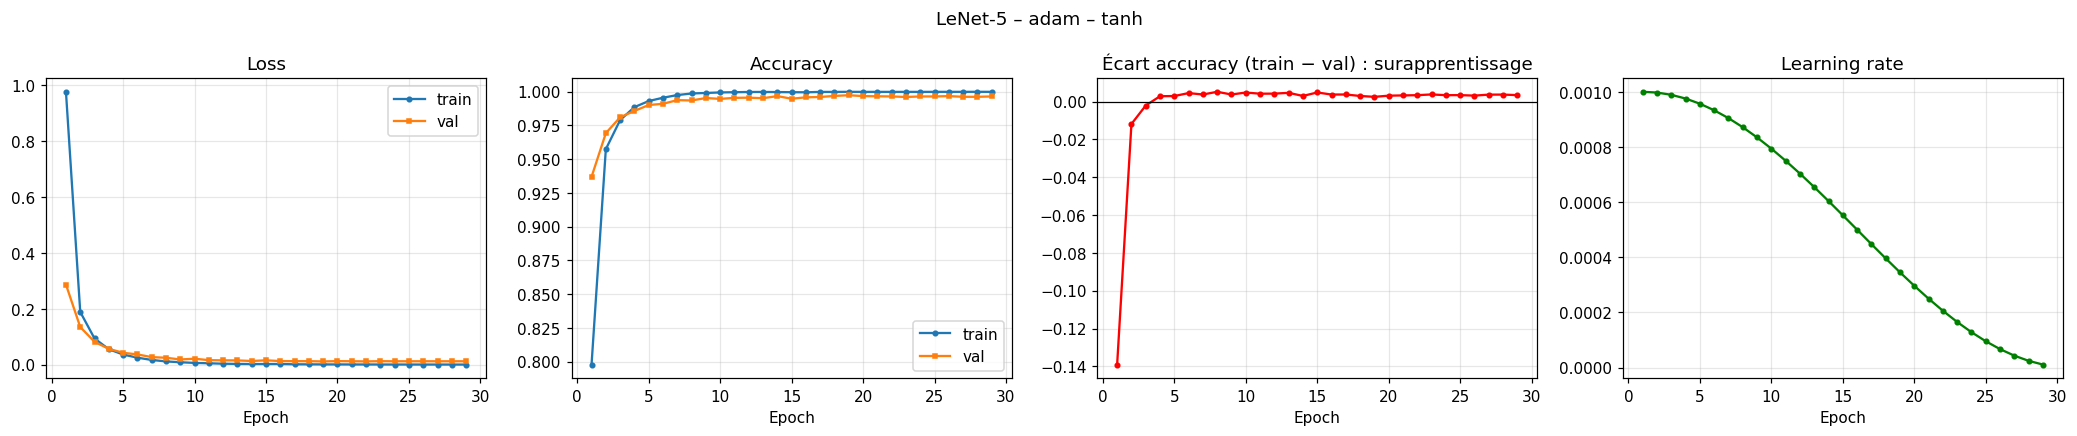

In [ ]:
def plot_history(h, title='LeNet-5', save=None):
    ep = range(1, len(h['train_loss']) + 1)
    fig, axs = plt.subplots(1, 4, figsize=(19, 4))
    axs[0].plot(ep, h['train_loss'], 'o-', ms=3, label='train'); axs[0].plot(ep, h['val_loss'], 's-', ms=3, label='val')
    axs[0].set_title('Loss'); axs[0].set_xlabel('Epoch'); axs[0].legend(); axs[0].grid(alpha=.3)
    axs[1].plot(ep, h['train_acc'], 'o-', ms=3, label='train'); axs[1].plot(ep, h['val_acc'], 's-', ms=3, label='val')
    axs[1].set_title('Accuracy'); axs[1].set_xlabel('Epoch'); axs[1].legend(); axs[1].grid(alpha=.3)
    gap = np.array(h['train_acc']) - np.array(h['val_acc'])
    axs[2].plot(ep, gap, 'r-o', ms=3); axs[2].axhline(0, color='k', lw=.8)
    axs[2].set_title('Écart accuracy (train − val) : surapprentissage'); axs[2].set_xlabel('Epoch'); axs[2].grid(alpha=.3)
    axs[3].plot(ep, h['lr'], 'g-o', ms=3); axs[3].set_title('Learning rate'); axs[3].set_xlabel('Epoch'); axs[3].grid(alpha=.3)
    plt.suptitle(title); plt.tight_layout()
    if save: plt.savefig(save)
    plt.show()

plot_history(history, f'LeNet-5 – {OPTIMIZER} – {ACTIVATION}', f'{OUT_DIR}/curves.png')

## 9. Évaluation sur le test : métriques, matrice de confusion, rapport par classe

In [ ]:
y_true, y_pred, y_prob = predict(model, test_loader)
test_acc = (y_true == y_pred).mean()
top3 = np.mean([y_true[i] in np.argsort(y_prob[i])[-3:] for i in range(len(y_true))])
top5 = np.mean([y_true[i] in np.argsort(y_prob[i])[-5:] for i in range(len(y_true))])
test_loss = F.nll_loss(torch.log(torch.from_numpy(y_prob) + 1e-12), torch.from_numpy(y_true)).item()
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
print(f'Test loss {test_loss:.4f} | Accuracy {test_acc:.4f} | Top-3 {top3:.4f} | Top-5 {top5:.4f}')
print(f'Macro Precision {p:.4f} | Macro Recall {r:.4f} | Macro F1 {f1:.4f}')

report = classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=class_names,
                               zero_division=0, output_dict=True)
report_df = pd.DataFrame(report).T
report_df.to_csv(f'{OUT_DIR}/classification_report.csv')
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=class_names, zero_division=0))

Test loss 0.0172 | Accuracy 0.9955 | Top-3 0.9991 | Top-5 0.9996
Macro Precision 0.9955 | Macro Recall 0.9955 | Macro F1 0.9955
              precision    recall  f1-score   support

          ya       1.00      1.00      1.00       234
          yi       1.00      1.00      1.00       234
          yu       1.00      1.00      1.00       234
         yab       1.00      1.00      1.00       234
         yad       0.99      1.00      1.00       234
         yae       1.00      1.00      1.00       234
         yaf       1.00      1.00      1.00       234
         yag       1.00      1.00      1.00       234
         yah       1.00      1.00      1.00       234
         yaj       1.00      1.00      1.00       234
         yak       1.00      1.00      1.00       234
         yal       1.00      0.99      1.00       234
         yam       1.00      1.00      1.00       234
         yan       1.00      1.00      1.00       234
         yaq       1.00      1.00      1.00       234
       

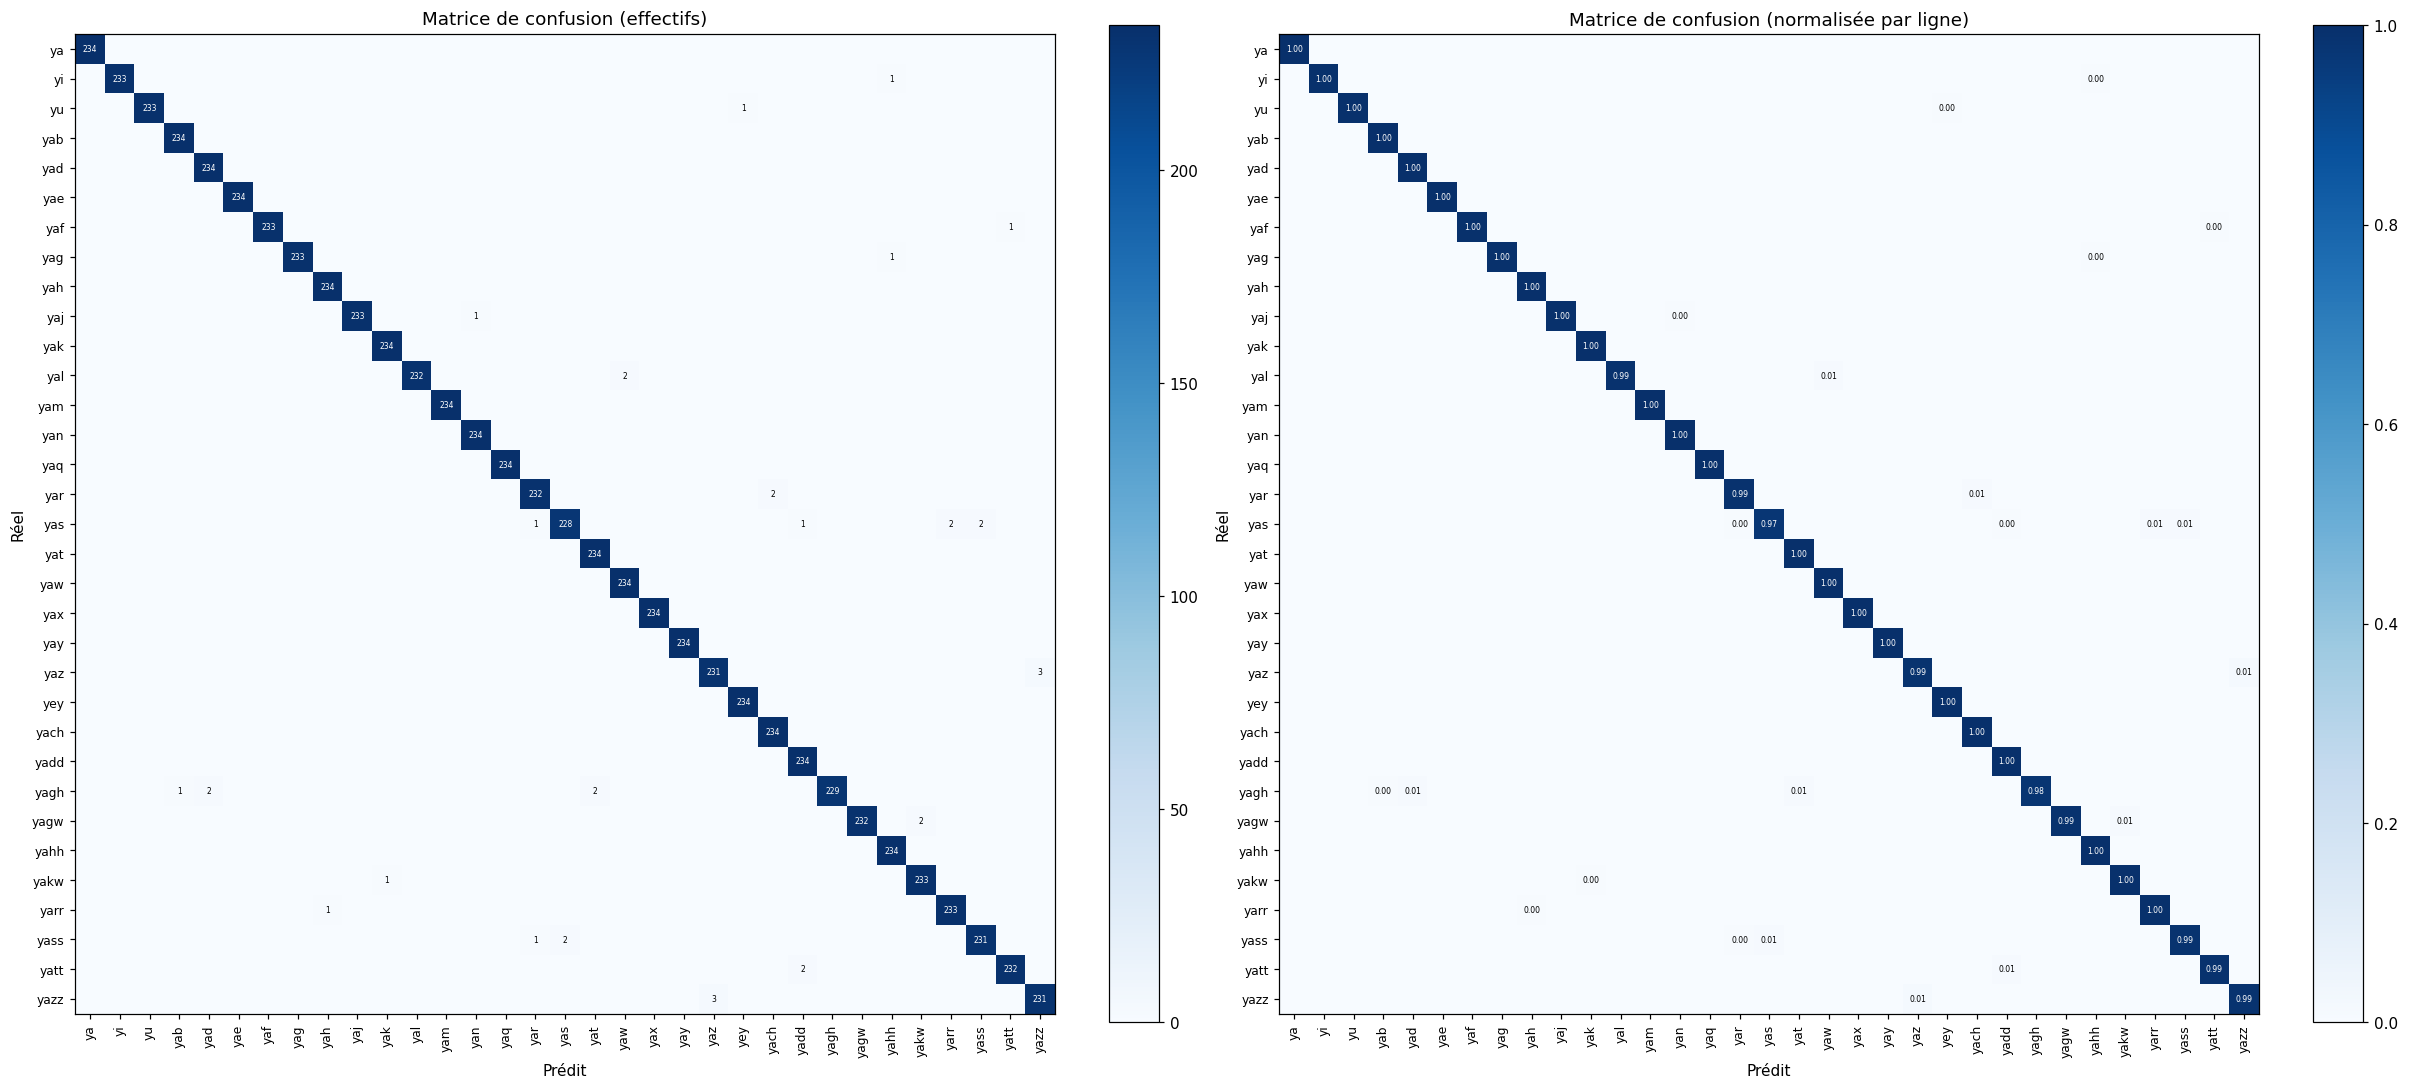

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axs = plt.subplots(1, 2, figsize=(22, 10))
for ax, M, title, fmt in [(axs[0], cm, 'Matrice de confusion (effectifs)', 'd'),
                          (axs[1], cm_norm, 'Matrice de confusion (normalisée par ligne)', '.2f')]:
    im = ax.imshow(M, cmap='Blues')
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(class_names, rotation=90, fontsize=8); ax.set_yticklabels(class_names, fontsize=8)
    ax.set_xlabel('Prédit'); ax.set_ylabel('Réel'); ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)
    thr = M.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if M[i, j] > 0:
                ax.text(j, i, format(M[i, j], fmt) if fmt == 'd' else f'{M[i, j]:.2f}',
                        ha='center', va='center', fontsize=5, color='white' if M[i, j] > thr else 'black')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrix.png'); plt.show()

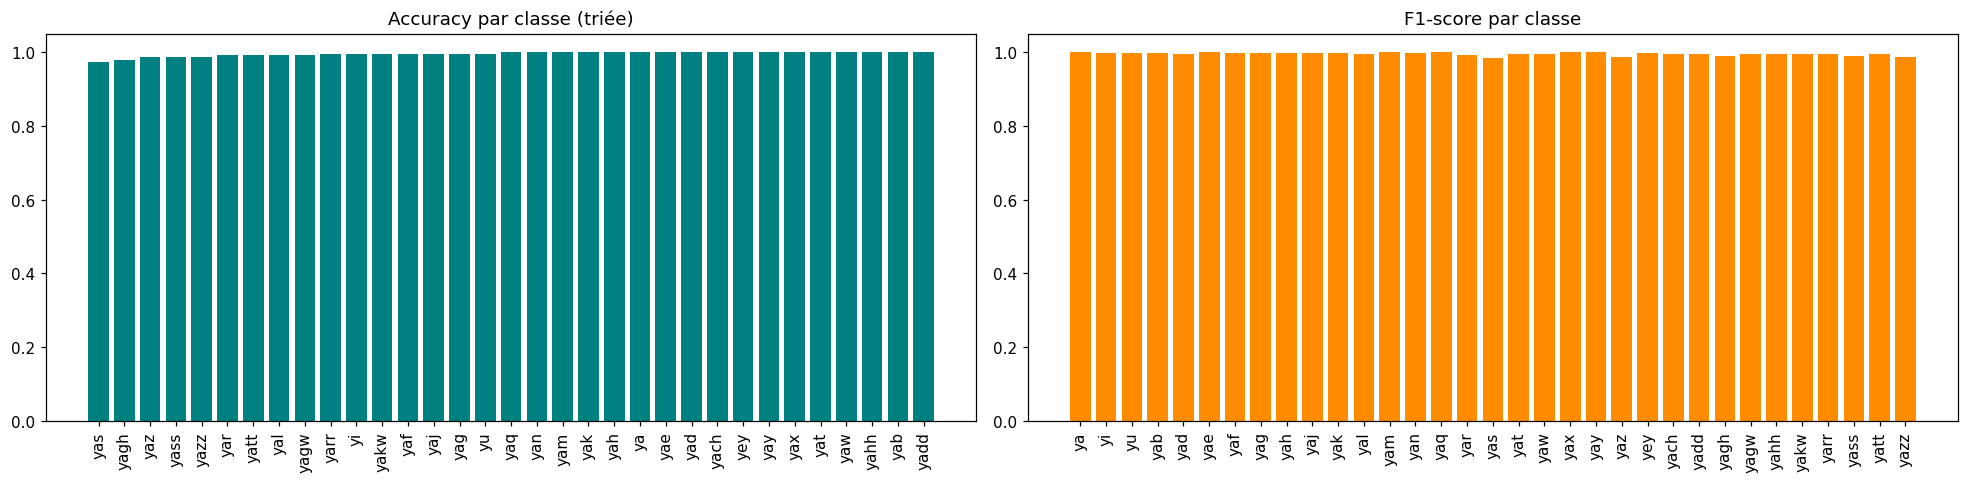

Confusions les plus fréquentes (réel -> prédit : nombre) :
  yaz -> yazz : 3
  yazz -> yaz : 3
  yagh -> yad : 2
  yar -> yach : 2
  yas -> yass : 2
  yas -> yarr : 2
  yagh -> yat : 2
  yagw -> yakw : 2
  yal -> yaw : 2
  yatt -> yadd : 2


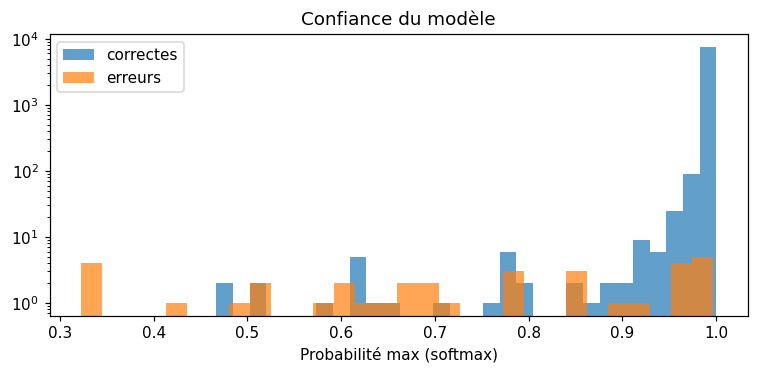

In [ ]:
# Accuracy / F1 par classe
per_class_acc = np.diag(cm_norm)
f1_cls = np.array([report[c]['f1-score'] for c in class_names])
order = np.argsort(per_class_acc)
fig, axs = plt.subplots(1, 2, figsize=(18, 4.5))
axs[0].bar(range(NUM_CLASSES), per_class_acc[order], color='teal')
axs[0].set_xticks(range(NUM_CLASSES)); axs[0].set_xticklabels(np.array(class_names)[order], rotation=90)
axs[0].set_title('Accuracy par classe (triée)'); axs[0].set_ylim(0, 1.05)
axs[1].bar(range(NUM_CLASSES), f1_cls, color='darkorange')
axs[1].set_xticks(range(NUM_CLASSES)); axs[1].set_xticklabels(class_names, rotation=90)
axs[1].set_title('F1-score par classe'); axs[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/per_class_metrics.png'); plt.show()

# Paires de classes les plus confondues
conf = cm.copy(); np.fill_diagonal(conf, 0)
top_pairs = np.dstack(np.unravel_index(np.argsort(conf.ravel())[::-1][:10], conf.shape))[0]
print('Confusions les plus fréquentes (réel -> prédit : nombre) :')
for i, j in top_pairs:
    if conf[i, j] > 0: print(f'  {class_names[i]} -> {class_names[j]} : {conf[i, j]}')

# Histogramme de confiance
conf_max = y_prob.max(1)
plt.figure(figsize=(7, 3.5))
plt.hist(conf_max[y_pred == y_true], bins=30, alpha=.7, label='correctes')
plt.hist(conf_max[y_pred != y_true], bins=30, alpha=.7, label='erreurs')
plt.yscale('log'); plt.xlabel('Probabilité max (softmax)'); plt.legend(); plt.title('Confiance du modèle')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confidence_hist.png'); plt.show()

## 10. Visualisations qualitatives : prédictions, erreurs, cartes caractéristiques, filtres

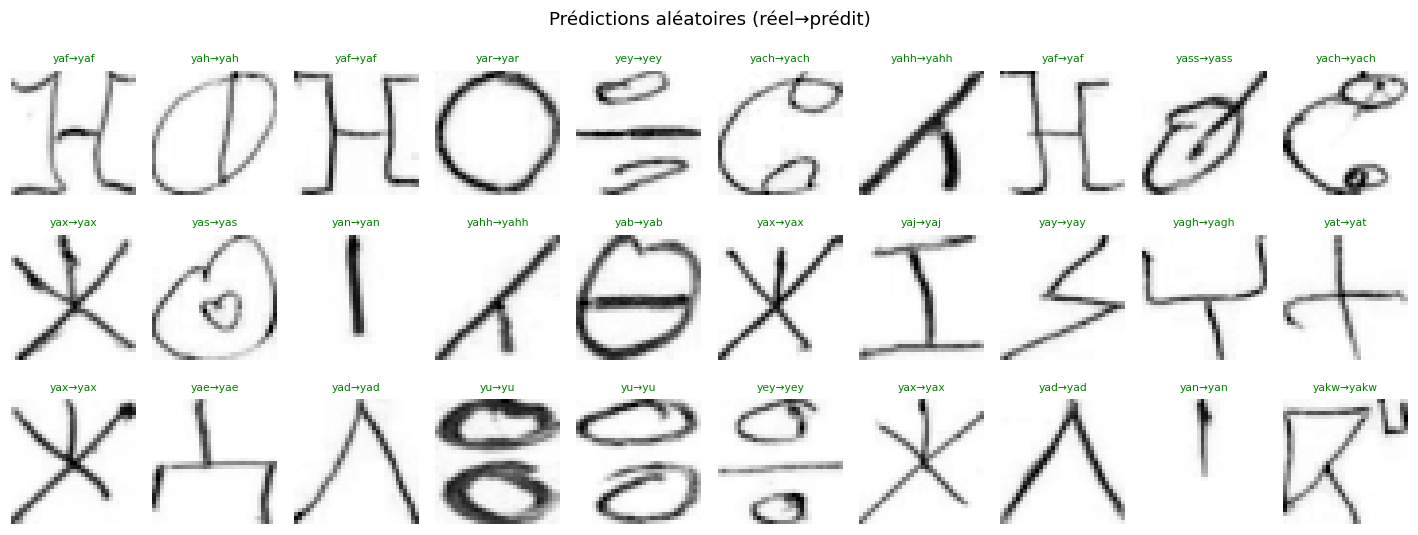

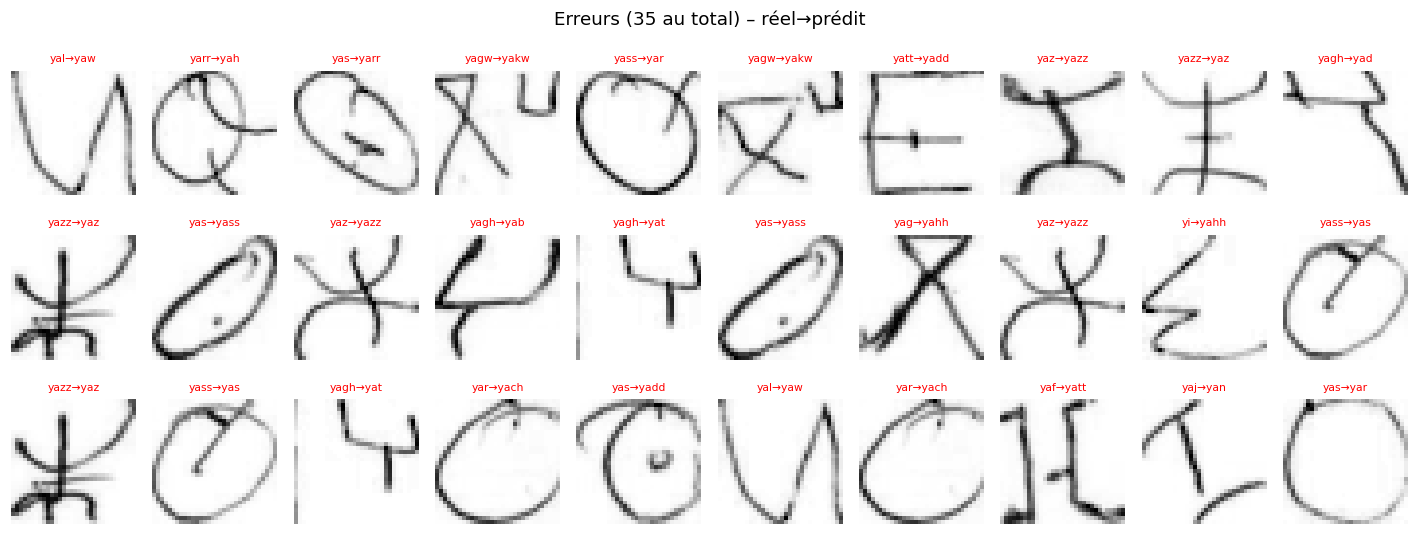

In [ ]:
test_X = torch.from_numpy(Xn[te_idx])

def show_predictions(ids, title, fname, ncols=10):
    ids = list(ids)[:ncols * 3]
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 1.3, nrows * 1.7))
    for ax in np.array(axs).ravel(): ax.axis('off')
    for ax, i in zip(np.array(axs).ravel(), ids):
        ax.imshow(denorm(test_X[i].numpy()), cmap='gray')
        ok = y_pred[i] == y_true[i]
        ax.set_title(f'{class_names[y_true[i]]}→{class_names[y_pred[i]]}', fontsize=7, color='green' if ok else 'red')
    plt.suptitle(title); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/{fname}'); plt.show()

rng = np.random.RandomState(SEED)
show_predictions(rng.choice(len(y_true), 30, replace=False), 'Prédictions aléatoires (réel→prédit)', 'predictions.png')
wrong = np.where(y_pred != y_true)[0]
if len(wrong): show_predictions(wrong, f'Erreurs ({len(wrong)} au total) – réel→prédit', 'errors.png')
else: print('Aucune erreur sur le test.')

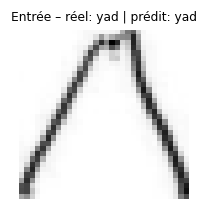

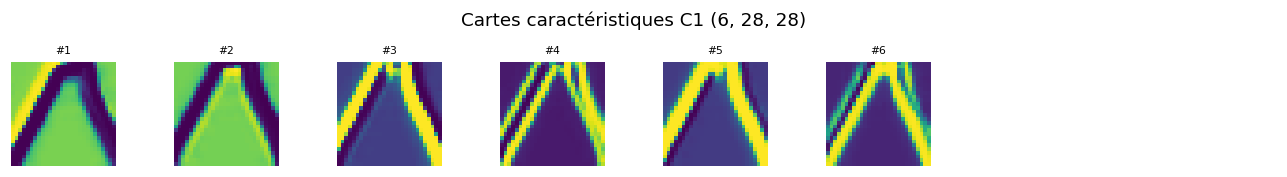

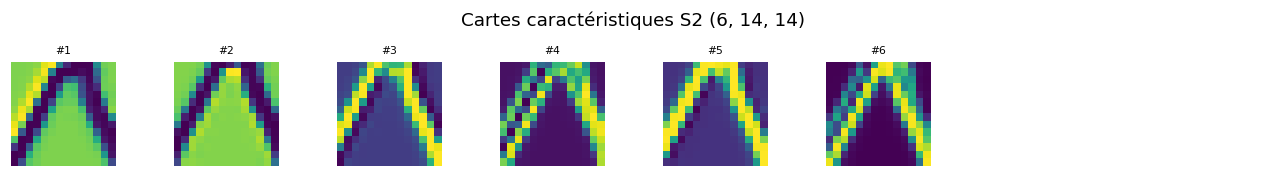

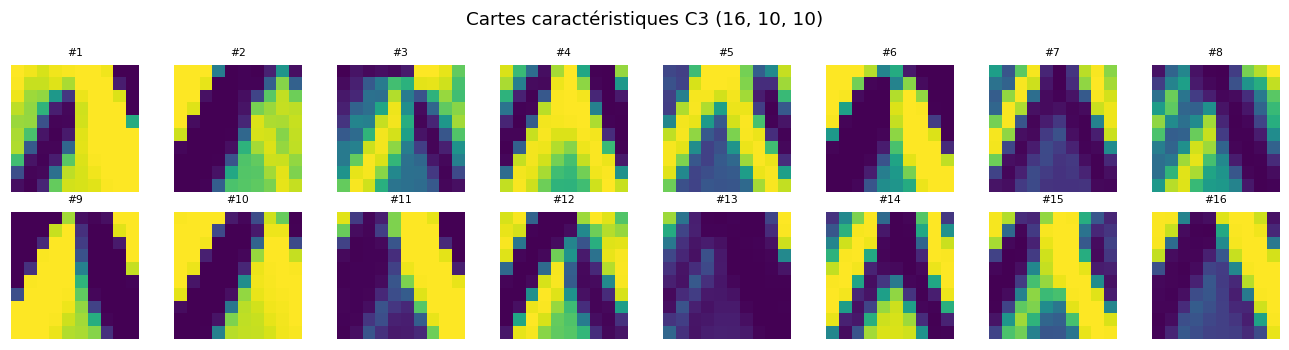

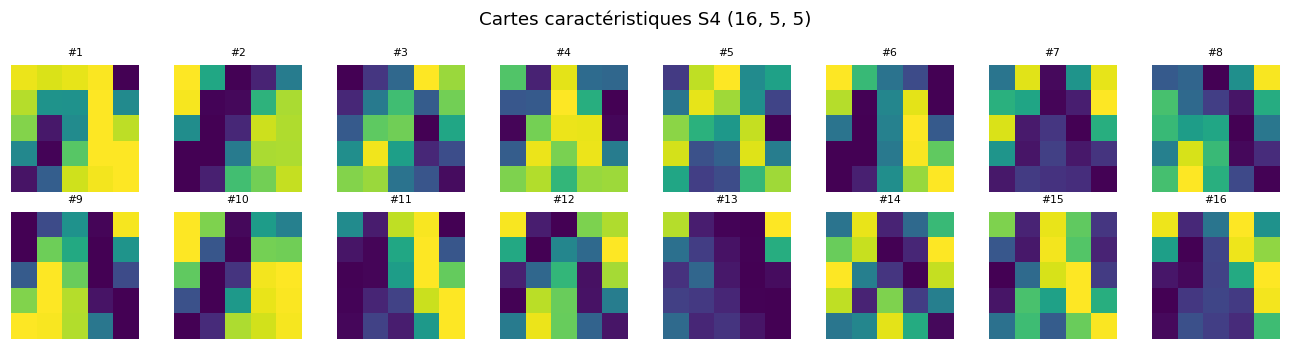

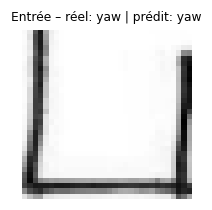

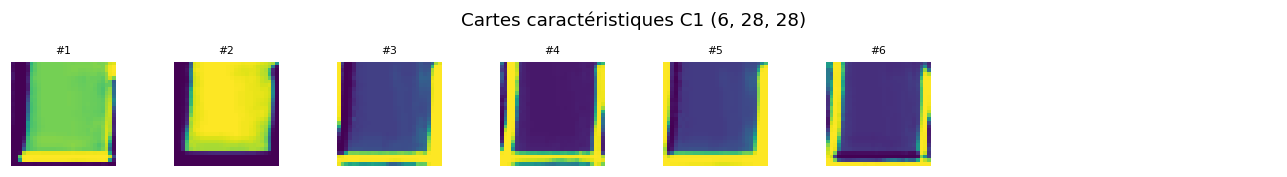

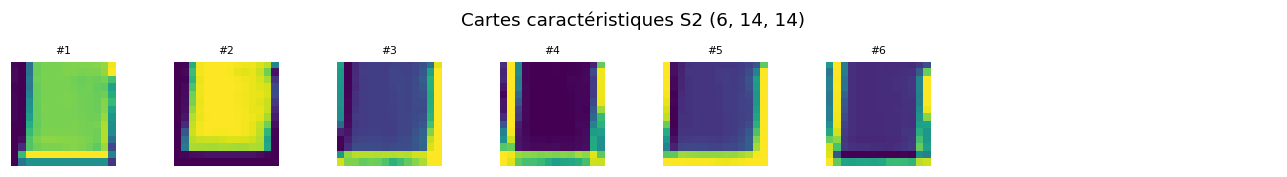

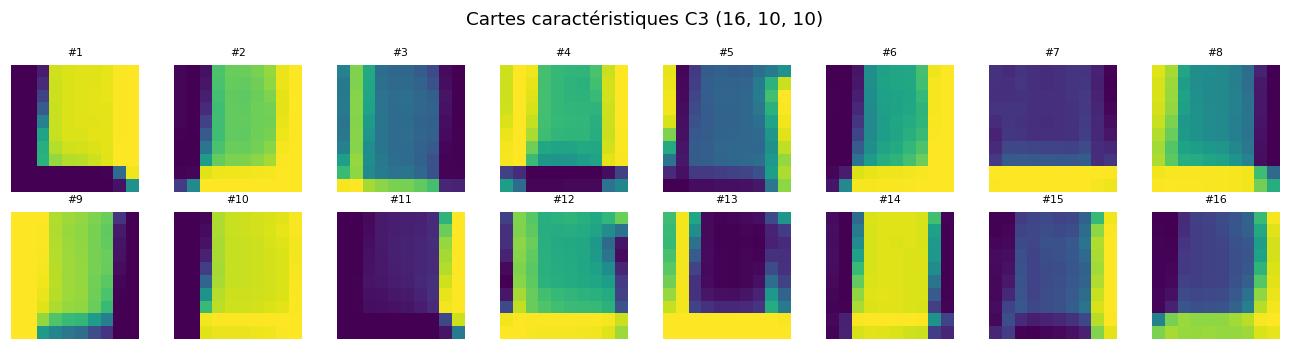

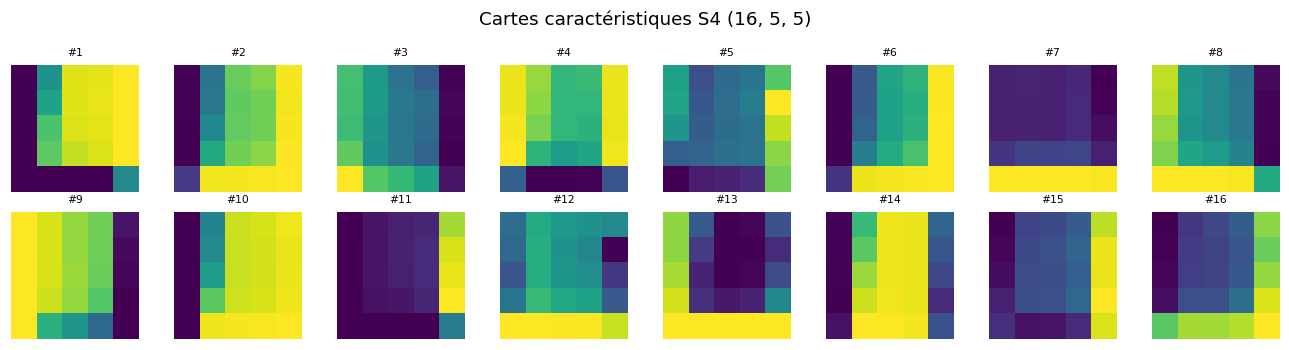

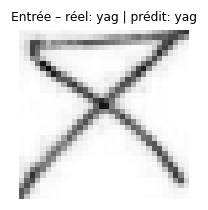

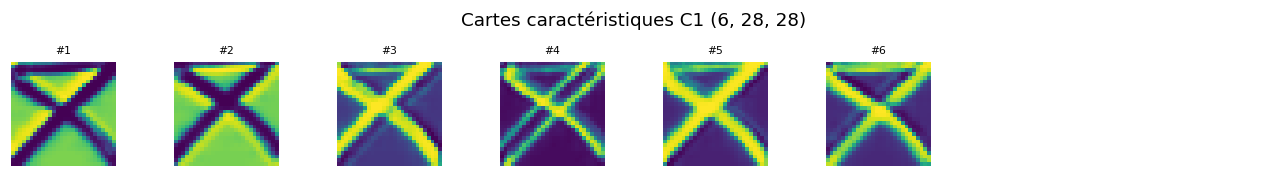

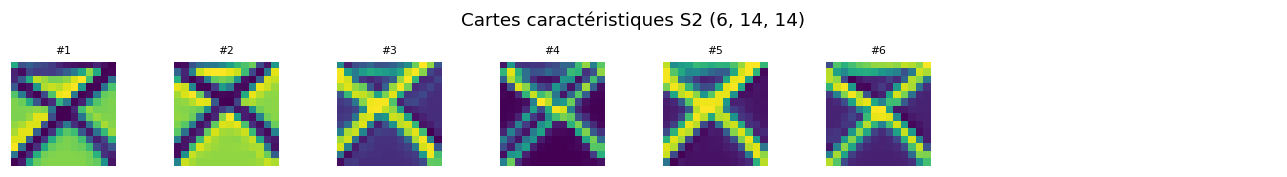

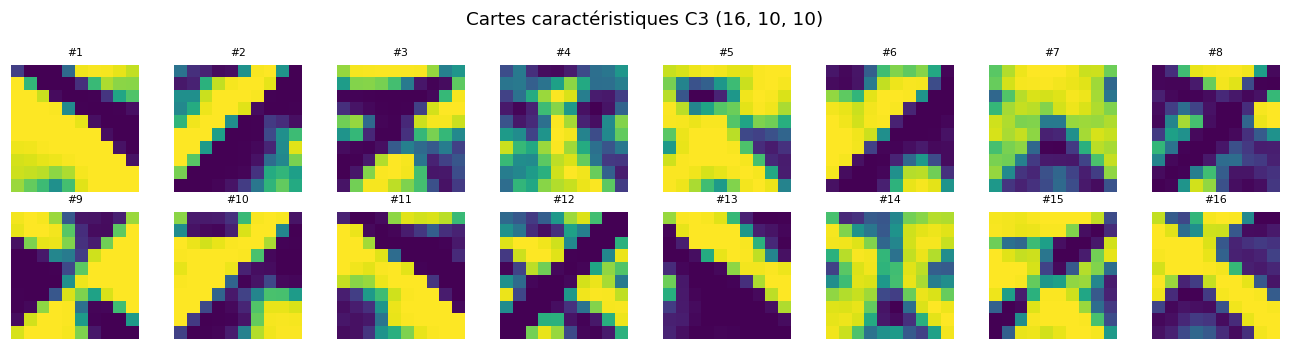

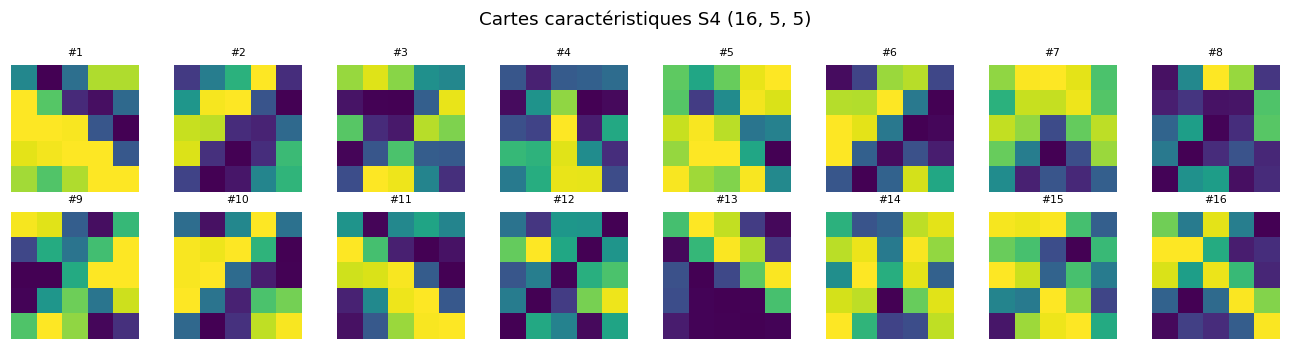

In [ ]:
def plot_maps(t, title, fname, ncols=8):
    t = t.detach().cpu().numpy()
    n = t.shape[0]; nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 1.5, nrows * 1.6))
    for ax in np.array(axs).ravel(): ax.axis('off')
    for k in range(n):
        ax = np.array(axs).ravel()[k]
        ax.imshow(t[k], cmap='viridis'); ax.set_title(f'#{k + 1}', fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/{fname}'); plt.show()

model.eval()
for k in [0, 1, 2]:   # trois images du test
    i = int(rng.randint(len(y_true)))
    x = test_X[i:i + 1].to(DEVICE)
    with torch.no_grad():
        _, maps = model(x, return_maps=True)
    plt.figure(figsize=(2, 2)); plt.imshow(denorm(test_X[i].numpy()), cmap='gray'); plt.axis('off')
    plt.title(f'Entrée – réel: {class_names[y_true[i]]} | prédit: {class_names[y_pred[i]]}', fontsize=8); plt.show()
    for name in ['C1', 'S2', 'C3', 'S4']:
        plot_maps(maps[name][0], f'Cartes caractéristiques {name} {tuple(maps[name].shape[1:])}', f'fmap_{k}_{name}.png')

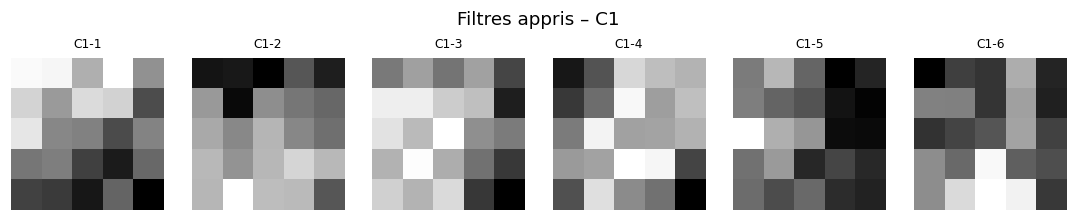

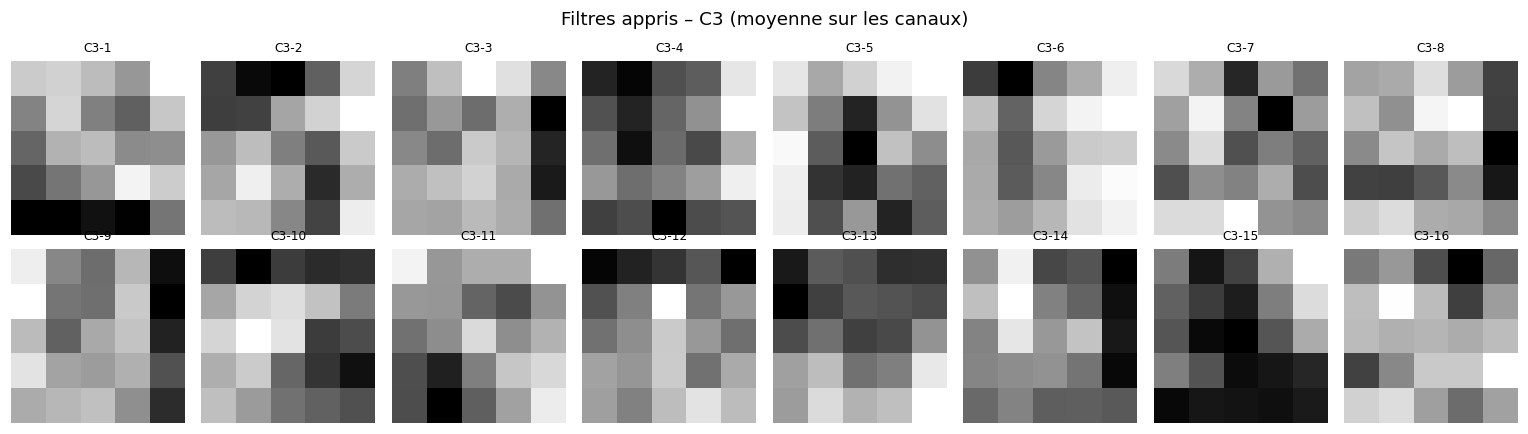

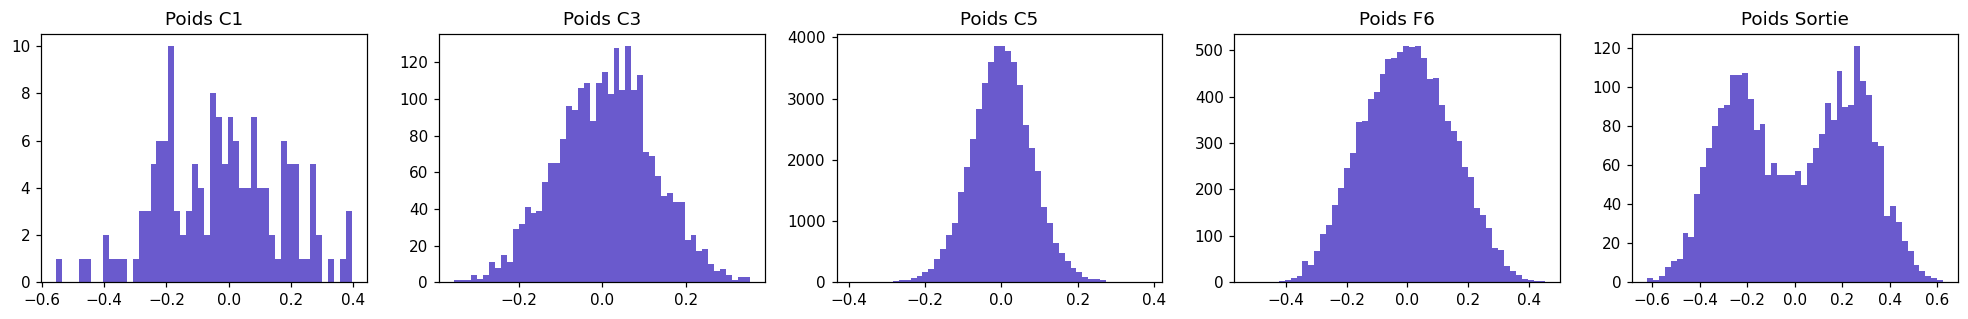

In [ ]:
# Filtres appris de C1 (6 filtres 5x5) et C3 (16 filtres 5x5, moyenne sur les canaux d'entrée)
w1 = model.c1[0].weight.detach().cpu().numpy()      # (6, C, 5, 5)
w3 = model.c3[0].weight.detach().cpu().numpy()      # (16, 6, 5, 5)
fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for k in range(6):
    axs[k].imshow(w1[k].mean(0), cmap='gray'); axs[k].axis('off'); axs[k].set_title(f'C1-{k + 1}', fontsize=8)
plt.suptitle('Filtres appris – C1'); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/filters_C1.png'); plt.show()
fig, axs = plt.subplots(2, 8, figsize=(14, 4))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(w3[k].mean(0), cmap='gray'); ax.axis('off'); ax.set_title(f'C3-{k + 1}', fontsize=8)
plt.suptitle('Filtres appris – C3 (moyenne sur les canaux)'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/filters_C3.png'); plt.show()

# Distribution des poids par couche
fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for ax, (n, w) in zip(axs, [('C1', model.c1[0].weight), ('C3', model.c3[0].weight), ('C5', model.c5[0].weight),
                            ('F6', model.f6[0].weight), ('Sortie', model.out.weight)]):
    ax.hist(w.detach().cpu().numpy().ravel(), bins=50, color='slateblue'); ax.set_title(f'Poids {n}')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/weights_hist.png'); plt.show()

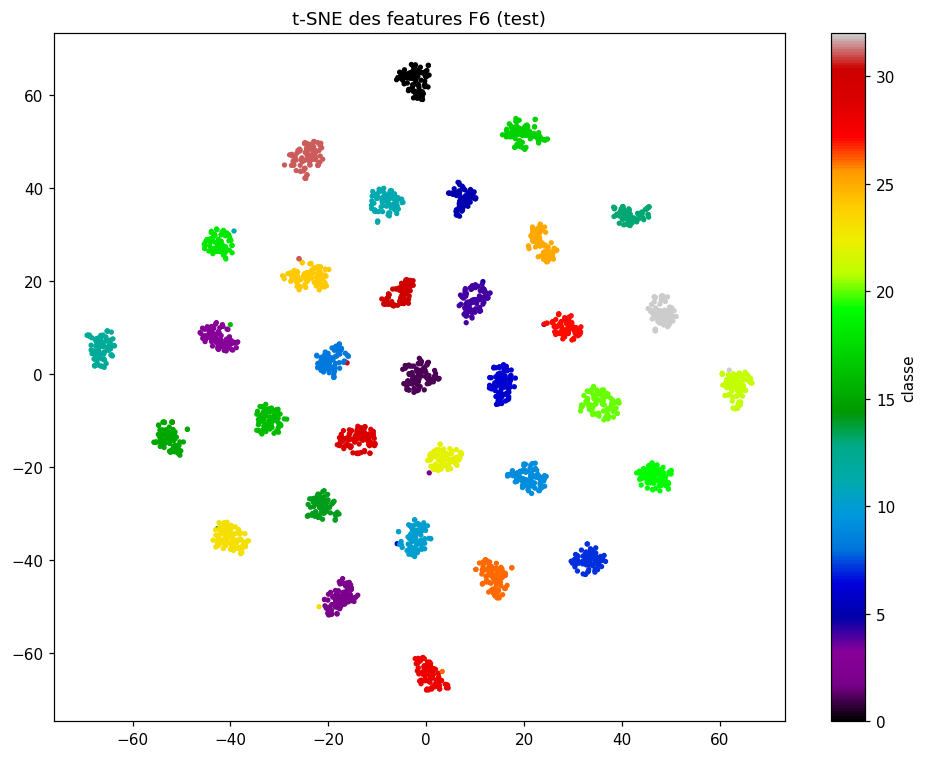

In [ ]:
# Projection t-SNE des 84 features de F6 (peut prendre 1-2 min)
from sklearn.manifold import TSNE
@torch.no_grad()
def get_features(m, X):
    m.eval(); out = []
    for i in range(0, len(X), 512):
        xb = X[i:i + 512].to(DEVICE)
        h = m.f6(m.c5(m.s4(m.c3(m.s2(m.c1(xb)))).flatten(1)))
        out.append(h.cpu())
    return torch.cat(out).numpy()

sub = rng.choice(len(y_true), min(3000, len(y_true)), replace=False)
emb = TSNE(n_components=2, init='pca', perplexity=30, random_state=SEED).fit_transform(get_features(model, test_X[sub]))
plt.figure(figsize=(9, 7))
sc = plt.scatter(emb[:, 0], emb[:, 1], c=y_true[sub], cmap='nipy_spectral', s=6)
plt.colorbar(sc, label='classe'); plt.title('t-SNE des features F6 (test)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/tsne.png'); plt.show()

## 11. Bonus : comparaison de tous les optimiseurs + variantes
Modifiez `OPT_LIST` pour choisir les optimiseurs, et `EPOCHS_CMP` pour réduire le temps (15 epochs par expérience).


=== sgd (tanh) ===
{'Expérience': 'sgd (tanh)', 'LR': 0.05, 'Train acc (fin)': 0.9665, 'Val acc (best)': 0.9599, 'Test acc': 0.9624, 'Val loss (min)': 0.1618, 'Temps (s)': 7}

=== sgd_momentum (tanh) ===
{'Expérience': 'sgd_momentum (tanh)', 'LR': 0.01, 'Train acc (fin)': 0.9878, 'Val acc (best)': 0.9824, 'Test acc': 0.9808, 'Val loss (min)': 0.0778, 'Temps (s)': 7}

=== nesterov (tanh) ===
{'Expérience': 'nesterov (tanh)', 'LR': 0.01, 'Train acc (fin)': 0.9879, 'Val acc (best)': 0.9825, 'Test acc': 0.9806, 'Val loss (min)': 0.0776, 'Temps (s)': 8}

=== adagrad (tanh) ===
{'Expérience': 'adagrad (tanh)', 'LR': 0.01, 'Train acc (fin)': 0.9932, 'Val acc (best)': 0.9873, 'Test acc': 0.9841, 'Val loss (min)': 0.0626, 'Temps (s)': 8}

=== adadelta (tanh) ===
{'Expérience': 'adadelta (tanh)', 'LR': 1.0, 'Train acc (fin)': 0.9999, 'Val acc (best)': 0.9964, 'Test acc': 0.9953, 'Val loss (min)': 0.0147, 'Temps (s)': 11}

=== rmsprop (tanh) ===
{'Expérience': 'rmsprop (tanh)', 'LR': 0.001, 'Tra

,Expérience,LR,Train acc (fin),Val acc (best),Test acc,Val loss (min),Temps (s)
0,adam (ReLU+BN+Dropout),0.001,0.9963,0.9973,0.9973,0.0108,10
1,rmsprop (tanh),0.001,0.9998,0.9961,0.9957,0.0155,8
2,nadam (tanh),0.001,0.9998,0.9952,0.9956,0.0180,10
3,adadelta (tanh),1.000,0.9999,0.9964,0.9953,0.0147,11
4,adam (tanh),0.001,0.9998,0.9952,0.9952,0.0186,10
5,adamw (tanh),0.001,0.9998,0.9952,0.9952,0.0188,9
6,amsgrad (tanh),0.001,0.9997,0.9953,0.9951,0.0219,9
7,adamax (tanh),0.002,0.9990,0.9942,0.9948,0.0279,9
8,adam (ReLU),0.001,0.9995,0.9951,0.9934,0.0170,7
9,adagrad (tanh),0.010,0.9932,0.9873,0.9841,0.0626,8


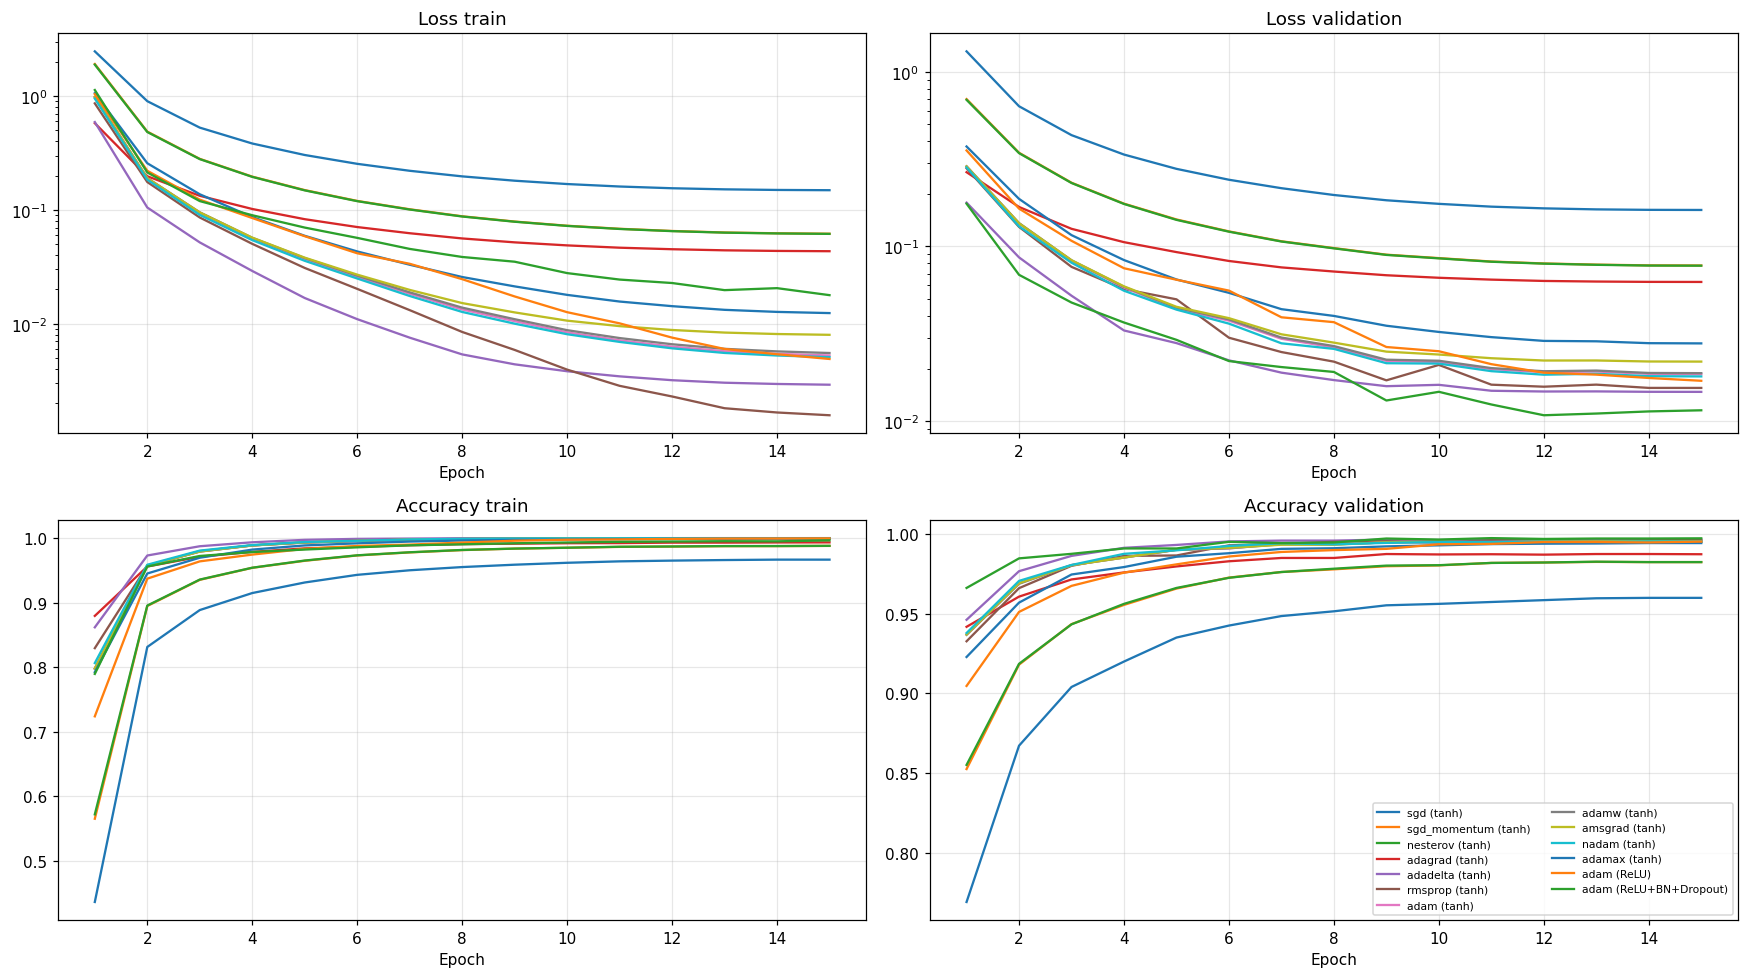

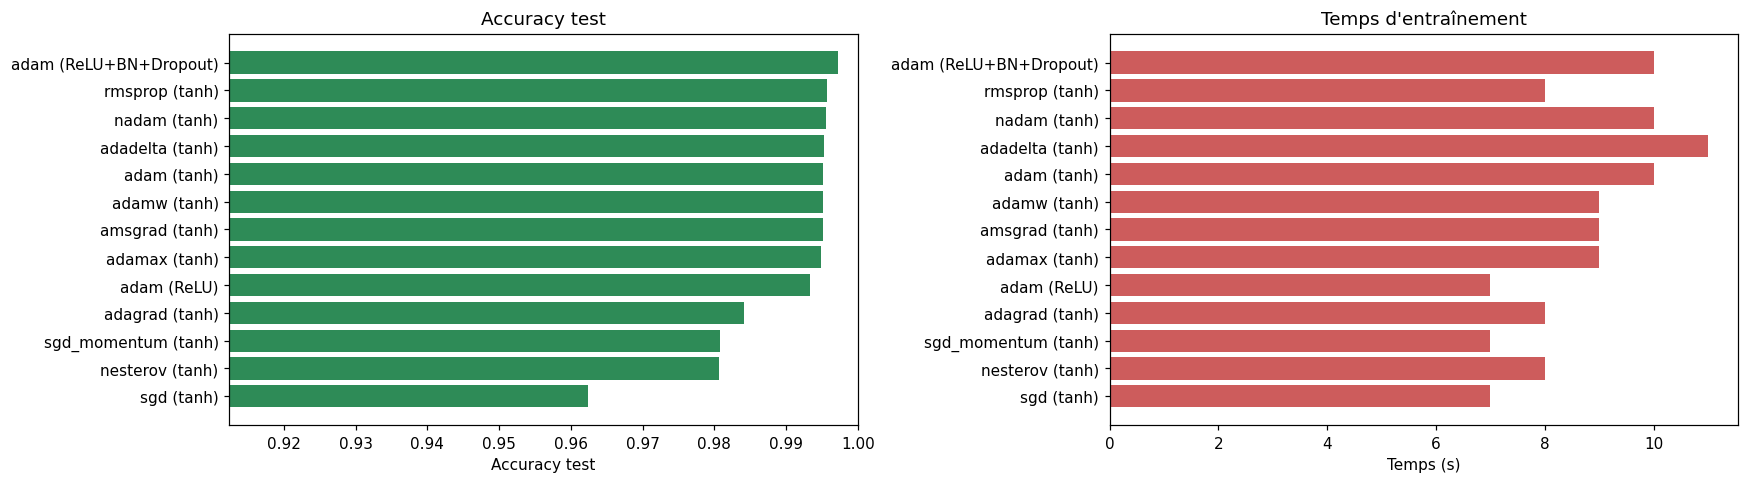

Epoch pour atteindre 90 % de val acc : {'sgd (tanh)': 3, 'sgd_momentum (tanh)': 2, 'nesterov (tanh)': 2, 'adagrad (tanh)': 1, 'adadelta (tanh)': 1, 'rmsprop (tanh)': 1, 'adam (tanh)': 1, 'adamw (tanh)': 1, 'amsgrad (tanh)': 1, 'nadam (tanh)': 1, 'adamax (tanh)': 1, 'adam (ReLU)': 1, 'adam (ReLU+BN+Dropout)': 1}


In [ ]:
EPOCHS_CMP = 15
OPT_LIST = ALL_OPTIMIZERS            # ex. ['sgd', 'adam', 'adamw'] pour aller plus vite
experiments = {f'{o} (tanh)': dict(opt=o, act='tanh') for o in OPT_LIST}
experiments['adam (ReLU)']            = dict(opt='adam', act='relu')
experiments['adam (ReLU+BN+Dropout)'] = dict(opt='adam', act='relu', bn=True, dropout=0.3)

results, rows = {}, []
for name, cfg in experiments.items():
    print(f'\n=== {name} ===')
    set_seed()
    m = LeNet5(act=cfg['act'], bn=cfg.get('bn', False), dropout=cfg.get('dropout', 0.0)).to(DEVICE)
    opt = get_optimizer(cfg['opt'], m.parameters())
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_CMP)
    t0 = time.time()
    h = train_model(m, opt, EPOCHS_CMP, scheduler=sch, verbose=False)
    dt = time.time() - t0
    yt, yp, _ = predict(m, test_loader)
    results[name] = h
    rows.append({'Expérience': name, 'LR': DEFAULT_LR[cfg['opt']], 'Train acc (fin)': round(h['train_acc'][-1], 4),
                 'Val acc (best)': round(h['best_val_acc'], 4), 'Test acc': round(float((yt == yp).mean()), 4),
                 'Val loss (min)': round(min(h['val_loss']), 4), 'Temps (s)': round(dt)})
    print(rows[-1])

cmp_df = pd.DataFrame(rows).sort_values('Test acc', ascending=False).reset_index(drop=True)
cmp_df.to_csv(f'{OUT_DIR}/comparison.csv', index=False)
display(cmp_df)

fig, axs = plt.subplots(2, 2, figsize=(16, 9))
for name, h in results.items():
    ep = range(1, len(h['val_acc']) + 1)
    axs[0, 0].plot(ep, h['train_loss'], label=name); axs[0, 1].plot(ep, h['val_loss'], label=name)
    axs[1, 0].plot(ep, h['train_acc'], label=name);  axs[1, 1].plot(ep, h['val_acc'], label=name)
for ax, t in zip(axs.ravel(), ['Loss train', 'Loss validation', 'Accuracy train', 'Accuracy validation']):
    ax.set_title(t); ax.set_xlabel('Epoch'); ax.grid(alpha=.3)
axs[0, 0].set_yscale('log'); axs[0, 1].set_yscale('log')
axs[1, 1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/comparison_curves.png'); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
axs[0].barh(cmp_df['Expérience'][::-1], cmp_df['Test acc'][::-1], color='seagreen')
axs[0].set_xlim(max(0, cmp_df['Test acc'].min() - 0.05), 1); axs[0].set_xlabel('Accuracy test'); axs[0].set_title('Accuracy test')
axs[1].barh(cmp_df['Expérience'][::-1], cmp_df['Temps (s)'][::-1], color='indianred')
axs[1].set_xlabel('Temps (s)'); axs[1].set_title("Temps d'entraînement")
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/comparison_bar.png'); plt.show()

# Vitesse de convergence : première epoch où la val acc dépasse 90 %
conv = {n: next((i + 1 for i, a in enumerate(h['val_acc']) if a >= 0.90), None) for n, h in results.items()}
print('Epoch pour atteindre 90 % de val acc :', conv)

## 12. Améliorations (bonus)

Améliorations testées une par une (**étude d'ablation**), puis combinées :

1. **Data augmentation** : rotation ±10°, translation ±10 %, zoom ±10 % (pas de flip : les caractères Tifinagh ne sont pas symétriques)
2. **ReLU** à la place de tanh · **Max-pooling** à la place du pooling moyen
3. **BatchNorm** : $\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}},\; y=\gamma\hat x+\beta$
4. **Dropout** (p = 0.3) sur les couches fully connected
5. **Label smoothing** : $y'_k=(1-\varepsilon)\,y_k+\varepsilon/K$ avec $\varepsilon=0.1$, $K=33$
6. **AdamW** (weight decay découplé) · **OneCycle LR** (warm-up puis décroissance cosinus)
7. **Architecture élargie** `LeNet5Plus` (32 et 64 filtres, FC 256-128)
8. **Ensemble** de 3 modèles (graines différentes) : $p(x)=\frac1M\sum_m p_m(x)$ + **TTA** (test-time augmentation)
9. **Grad-CAM** : $\alpha_k^c=\frac1Z\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},\; L^c=\mathrm{ReLU}\big(\sum_k\alpha_k^cA^k\big)$

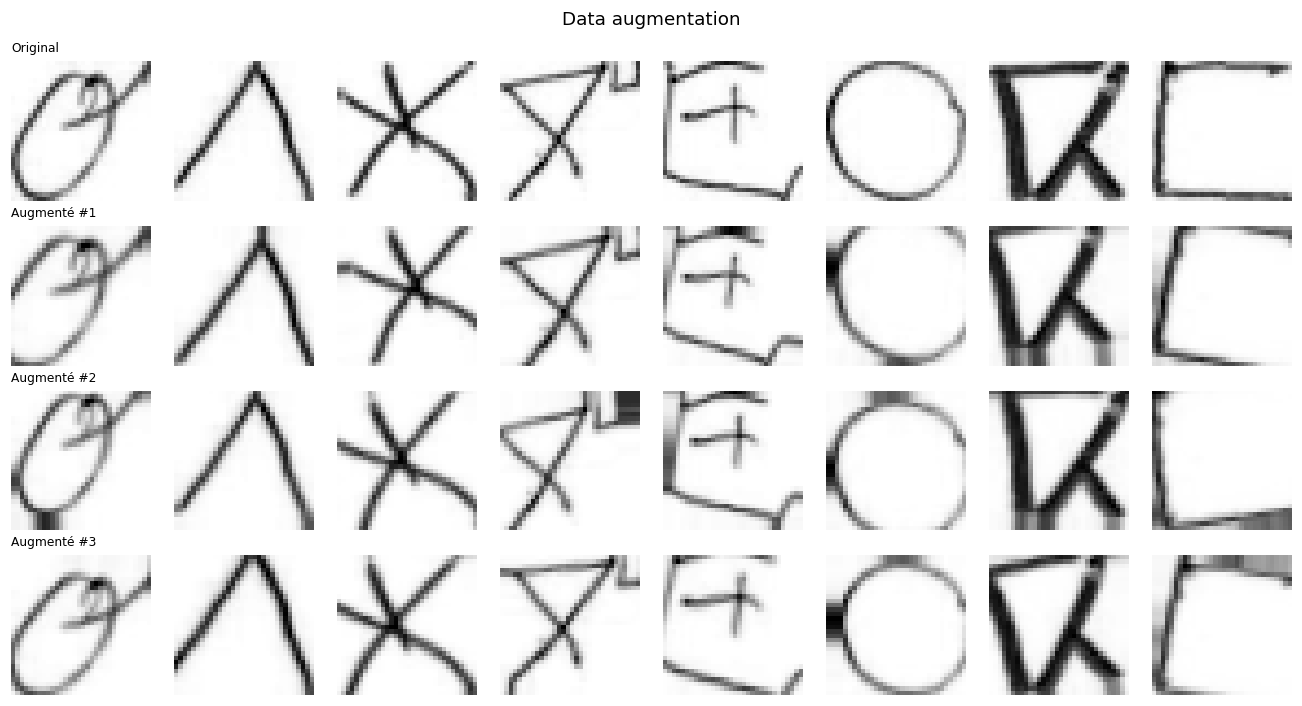

In [ ]:
base_pred, base_true = y_pred.copy(), y_true.copy()      # résultats du modèle de base (section 9)

def affine(x, ang_deg, sc, tx, ty):
    # Transformation affine différentiable d'un batch (rotation, zoom, translation)
    B = x.size(0)
    ang = ang_deg * np.pi / 180
    ang, sc, tx, ty = [torch.as_tensor(v, dtype=x.dtype, device=x.device).expand(B) for v in (ang, sc, tx, ty)]
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)   # (B, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode='border', align_corners=False)

def augment_batch(x, rot=10, shift=0.10, scale=0.10):
    B, d = x.size(0), x.device
    r = lambda a: (torch.rand(B, device=d) * 2 - 1) * a
    return affine(x, r(rot), 1 + r(scale), r(shift * 2), r(shift * 2))

# Visualisation de l'augmentation
xs = test_X[:8] if 'test_X' in globals() else torch.from_numpy(Xn[te_idx][:8])
fig, axs = plt.subplots(4, 8, figsize=(12, 6.5))
for row in range(4):
    xa = xs if row == 0 else augment_batch(xs)
    for k in range(8):
        axs[row, k].imshow(denorm(xa[k].numpy()), cmap='gray'); axs[row, k].axis('off')
    axs[row, 0].set_title('Original' if row == 0 else f'Augmenté #{row}', fontsize=8, loc='left')
plt.suptitle('Data augmentation'); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/augmentation.png'); plt.show()

In [ ]:
class LeNet5Plus(nn.Module):
    # Version élargie de LeNet-5 : plus de filtres, padding 'same' sur C1
    def __init__(self, in_ch=CHANNELS, n_classes=NUM_CLASSES, ch=(32, 64), fc=(256, 128),
                 act='relu', pool='max', dropout=0.3, bn=True):
        super().__init__()
        self.c1  = conv_layer(in_ch, ch[0], 5, padding=2, act=act, bn=bn)   # 32 -> 32
        self.s2  = pool_layer(pool)                                         # 32 -> 16
        self.c3  = conv_layer(ch[0], ch[1], 5, act=act, bn=bn)              # 16 -> 12
        self.s4  = pool_layer(pool)                                         # 12 -> 6
        self.c5  = fc_layer(ch[1] * 6 * 6, fc[0], act, dropout, bn)
        self.f6  = fc_layer(fc[0], fc[1], act, dropout, bn)
        self.out = nn.Linear(fc[1], n_classes)
    def forward(self, x, return_maps=False):
        a1 = self.c1(x); p2 = self.s2(a1)
        a3 = self.c3(p2); p4 = self.s4(a3)
        o = self.out(self.f6(self.c5(p4.flatten(1))))
        return (o, {'C1': a1, 'S2': p2, 'C3': a3, 'S4': p4}) if return_maps else o

BASE = dict(act='tanh', pool='avg', bn=False, dropout=0.0, aug=False, ls=0.0, opt='adam', sched='cosine', wide=False)
def C(**kw): return {**BASE, **kw}

def build_model(cfg):
    cls = LeNet5Plus if cfg['wide'] else LeNet5
    return cls(act=cfg['act'], pool=cfg['pool'], bn=cfg['bn'], dropout=cfg['dropout']).to(DEVICE)

def run_epoch_v2(model, loader, optimizer=None, crit=None, augment=False, scheduler=None):
    train = optimizer is not None
    crit = crit if crit is not None else criterion
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if train and augment:
                xb = augment_batch(xb)
            out = model(xb)
            loss = crit(out, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
                if scheduler is not None: scheduler.step()      # scheduler par batch (OneCycle)
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n

def train_model_v2(model, optimizer, epochs, scheduler=None, per_batch=False, augment=False,
                   label_smoothing=0.0, patience=None, verbose=False):
    train_crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'lr': []}
    best_acc, best_state, bad = -1.0, None, 0
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch_v2(model, train_loader, optimizer, train_crit, augment, scheduler if per_batch else None)
        vl, va = run_epoch_v2(model, val_loader)               # val loss = cross-entropy standard (comparable)
        hist['lr'].append(optimizer.param_groups[0]['lr'])
        if scheduler is not None and not per_batch: scheduler.step()
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va]): hist[k].append(v)
        if va > best_acc:
            best_acc, bad, best_state = va, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if verbose: print(f'Epoch {ep:02d}/{epochs} | loss {tl:.4f}/{vl:.4f} | acc {ta:.4f}/{va:.4f}')
        if patience and bad >= patience:
            print(f"  early stopping à l'epoch {ep}"); break
    model.load_state_dict(best_state)
    hist['best_val_acc'] = best_acc
    return hist

def train_cfg(cfg, epochs, seed=SEED, patience=None, verbose=False):
    set_seed(seed)
    m = build_model(cfg)
    lr = DEFAULT_LR[cfg['opt']]
    opt = get_optimizer(cfg['opt'], m.parameters(), lr)
    per_batch, sch = False, None
    if cfg['sched'] == 'cosine':
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    elif cfg['sched'] == 'onecycle':
        sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr * 3, epochs=epochs,
                                                  steps_per_epoch=len(train_loader), cycle_momentum=False)
        per_batch, patience = True, None          # pas d'early stopping avec OneCycle
    elif cfg['sched'] == 'step':
        sch = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs // 3), gamma=0.3)
    t0 = time.time()
    h = train_model_v2(m, opt, epochs, sch, per_batch, cfg['aug'], cfg['ls'], patience, verbose)
    h['time'] = time.time() - t0
    return m, h

### 12.1 Étude d'ablation : effet de chaque amélioration (20 epochs chacune)

=== 0 Baseline (tanh, avg, Adam) ===
{'Configuration': '0 Baseline (tanh, avg, Adam)', 'Paramètres': 63661, 'Val acc (best)': 0.9959, 'Test acc': 0.9952, 'Temps (s)': 11}
=== 1 + ReLU ===
{'Configuration': '1 + ReLU', 'Paramètres': 63661, 'Val acc (best)': 0.9961, 'Test acc': 0.9939, 'Temps (s)': 12}
=== 2 + MaxPool ===
{'Configuration': '2 + MaxPool', 'Paramètres': 63661, 'Val acc (best)': 0.9968, 'Test acc': 0.9959, 'Temps (s)': 13}
=== 3 + BatchNorm ===
{'Configuration': '3 + BatchNorm', 'Paramètres': 64113, 'Val acc (best)': 0.9977, 'Test acc': 0.9965, 'Temps (s)': 15}
=== 4 + Dropout 0.3 ===
{'Configuration': '4 + Dropout 0.3', 'Paramètres': 63661, 'Val acc (best)': 0.9942, 'Test acc': 0.9939, 'Temps (s)': 13}
=== 5 + Augmentation ===
{'Configuration': '5 + Augmentation', 'Paramètres': 63661, 'Val acc (best)': 0.9946, 'Test acc': 0.9939, 'Temps (s)': 14}
=== 6 + Label smoothing ===
{'Configuration': '6 + Label smoothing', 'Paramètres': 63661, 'Val acc (best)': 0.9965, 'Test acc': 

,Configuration,Paramètres,Val acc (best),Test acc,Temps (s),Gain test vs baseline
0,"0 Baseline (tanh, avg, Adam)",63661,0.9959,0.9952,11,0.0000
1,1 + ReLU,63661,0.9961,0.9939,12,-0.0013
2,2 + MaxPool,63661,0.9968,0.9959,13,0.0007
3,3 + BatchNorm,64113,0.9977,0.9965,15,0.0013
4,4 + Dropout 0.3,63661,0.9942,0.9939,13,-0.0013
5,5 + Augmentation,63661,0.9946,0.9939,14,-0.0013
6,6 + Label smoothing,63661,0.9965,0.9964,12,0.0012
7,7 + AdamW,63661,0.9962,0.9952,12,0.0000
8,8 + OneCycle,63661,0.9968,0.9961,12,0.0009
9,9 Tout combiné (LeNet-5),64113,0.9946,0.9946,16,-0.0006


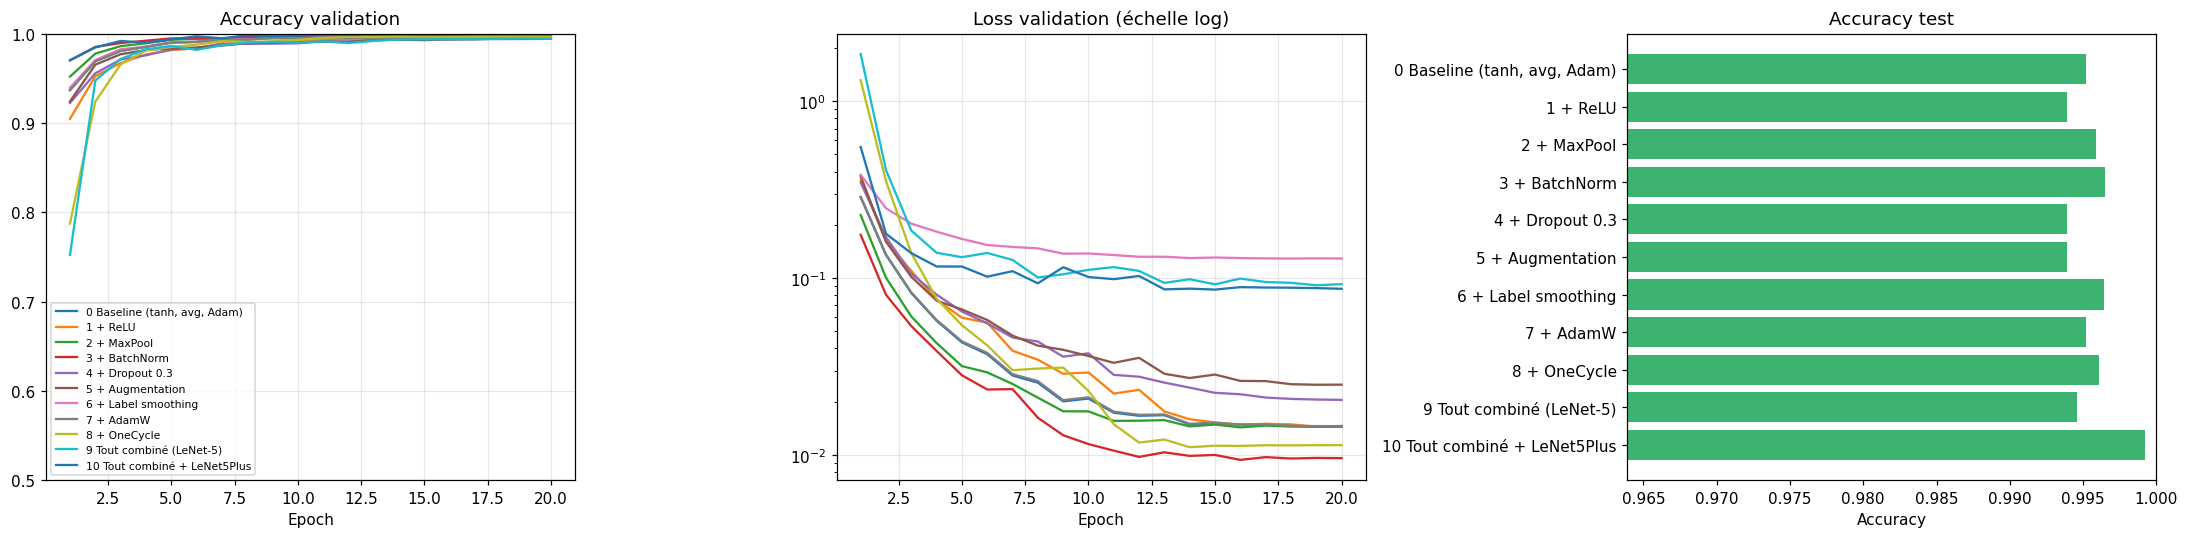

In [ ]:
EPOCHS_ABL = 20
ALL_ON = dict(act='relu', pool='max', bn=True, dropout=0.3, aug=True, ls=0.1, opt='adamw', sched='onecycle')
abl_cfgs = {
    '0 Baseline (tanh, avg, Adam)':  C(),
    '1 + ReLU':                      C(act='relu'),
    '2 + MaxPool':                   C(pool='max'),
    '3 + BatchNorm':                 C(bn=True),
    '4 + Dropout 0.3':               C(dropout=0.3),
    '5 + Augmentation':              C(aug=True),
    '6 + Label smoothing':           C(ls=0.1),
    '7 + AdamW':                     C(opt='adamw'),
    '8 + OneCycle':                  C(sched='onecycle'),
    '9 Tout combiné (LeNet-5)':      C(**ALL_ON),
    '10 Tout combiné + LeNet5Plus':  C(**ALL_ON, wide=True),
}
abl_results, abl_rows = {}, []
for name, cfg in abl_cfgs.items():
    print(f'=== {name} ===')
    m, h = train_cfg(cfg, EPOCHS_ABL)
    yt, yp, _ = predict(m, test_loader)
    abl_results[name] = h
    abl_rows.append({'Configuration': name, 'Paramètres': count_params(m),
                     'Val acc (best)': round(h['best_val_acc'], 4), 'Test acc': round(float((yt == yp).mean()), 4),
                     'Temps (s)': round(h['time'])})
    print(abl_rows[-1])
    del m

abl_df = pd.DataFrame(abl_rows)
abl_df['Gain test vs baseline'] = (abl_df['Test acc'] - abl_df['Test acc'].iloc[0]).round(4)
abl_df.to_csv(f'{OUT_DIR}/ablation.csv', index=False)
display(abl_df)

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for name, h in abl_results.items():
    ep = range(1, len(h['val_acc']) + 1)
    axs[0].plot(ep, h['val_acc'], label=name); axs[1].plot(ep, h['val_loss'], label=name)
axs[0].set_title('Accuracy validation'); axs[1].set_title('Loss validation (échelle log)'); axs[1].set_yscale('log')
axs[0].set_ylim(0.5, 1.0)
for ax in axs[:2]: ax.set_xlabel('Epoch'); ax.grid(alpha=.3)
axs[0].legend(fontsize=7)
axs[2].barh(abl_df['Configuration'][::-1], abl_df['Test acc'][::-1], color='mediumseagreen')
axs[2].set_xlim(max(0, abl_df['Test acc'].min() - 0.03), 1); axs[2].set_title('Accuracy test'); axs[2].set_xlabel('Accuracy')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/ablation_curves.png'); plt.show()

### 12.2 Modèle final : meilleure configuration, 3 graines, ensemble + TTA

Meilleure configuration (validation) : 10 Tout combiné + LeNet5Plus
--- graine 42 ---
  val acc : 0.9996 | temps 67 s
--- graine 43 ---
  val acc : 0.9996 | temps 68 s
--- graine 44 ---
  val acc : 0.9996 | temps 68 s


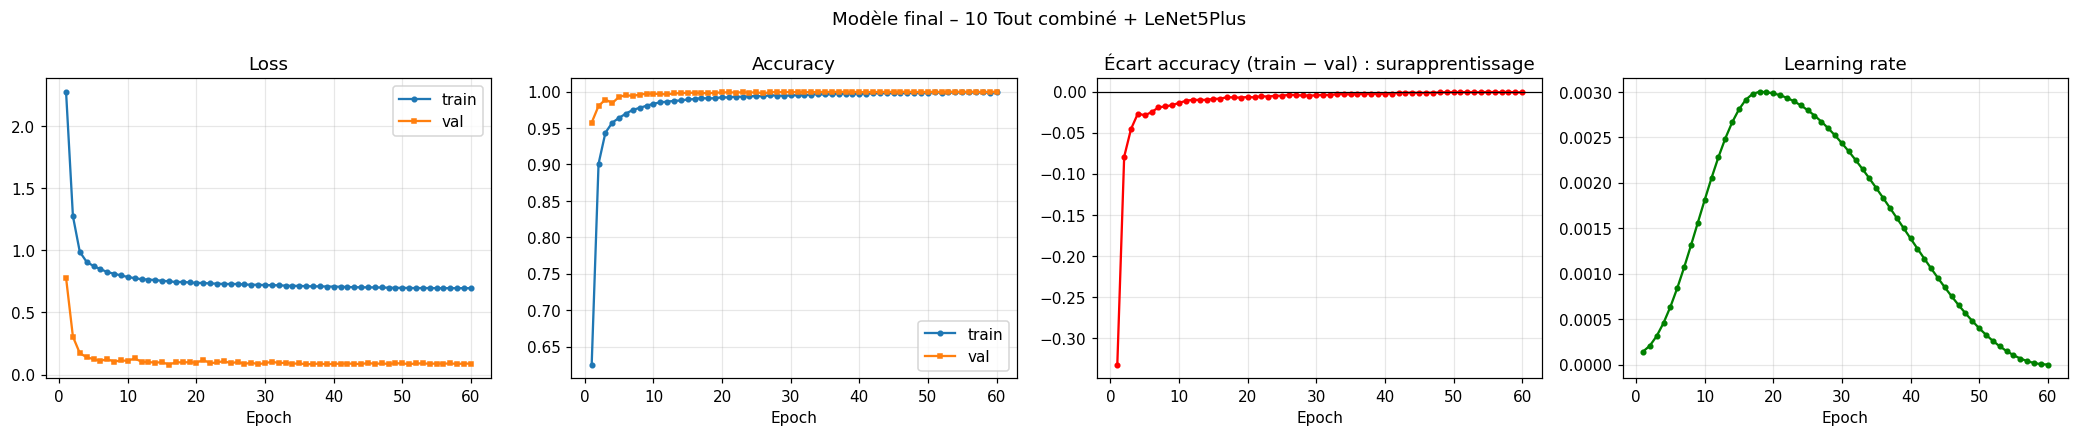

,Modèle,Test acc,Macro-F1
0,LeNet-5 de base (section 7),0.9955,0.9955
1,Amélioré – graine 42,0.9984,0.9984
2,Amélioré – graine 43,0.9991,0.9991
3,Amélioré – graine 44,0.9997,0.9997
4,Ensemble de 3 modèles,0.9997,0.9997
5,Ensemble de 3 + TTA,0.9997,0.9997


Moyenne ± écart-type (3 graines) : 0.9991 ± 0.0005


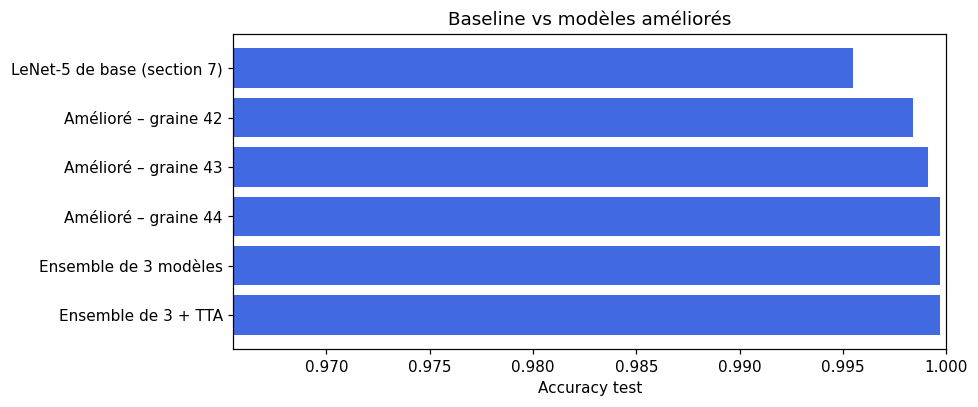

In [ ]:
FINAL_EPOCHS = 60
SEEDS = [42, 43, 44]
best_name = max(abl_results, key=lambda n: abl_results[n]['best_val_acc'])   # choisi sur la validation (pas le test)
best_cfg = abl_cfgs[best_name]
print('Meilleure configuration (validation) :', best_name)

final_models, final_hist = [], []
for sd in SEEDS:
    print(f'--- graine {sd} ---')
    m, h = train_cfg(best_cfg, FINAL_EPOCHS, seed=sd, patience=15)
    torch.save(m.state_dict(), f'{OUT_DIR}/final_seed{sd}.pt')
    final_models.append(m); final_hist.append(h)
    print('  val acc :', round(h['best_val_acc'], 4), '| temps', round(h['time']), 's')

plot_history(final_hist[0], f'Modèle final – {best_name}', f'{OUT_DIR}/final_curves.png')

@torch.no_grad()
def predict_tta(models, loader, tta=True):
    # (angle°, zoom, tx, ty)
    T = [(0, 1, 0, 0)]
    if tta:
        T += [(5, 1, 0, 0), (-5, 1, 0, 0), (0, 1, .06, 0), (0, 1, -.06, 0), (0, 1, 0, .06), (0, 1, 0, -.06),
              (0, 1.08, 0, 0), (0, .92, 0, 0)]
    probs, ys = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE); p = 0
        for m in models:
            m.eval()
            for (a, s, tx, ty) in T:
                xt = xb if (a, s, tx, ty) == (0, 1, 0, 0) else affine(xb, a, s, tx, ty)
                p = p + F.softmax(m(xt), 1)
        probs.append((p / (len(models) * len(T))).cpu()); ys.append(yb)
    probs = torch.cat(probs).numpy(); ys = torch.cat(ys).numpy()
    return ys, probs.argmax(1), probs

def summarize(name, yt, yp):
    _, _, f1m, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    return {'Modèle': name, 'Test acc': round(float((yt == yp).mean()), 4), 'Macro-F1': round(float(f1m), 4)}

rows = [summarize('LeNet-5 de base (section 7)', base_true, base_pred)]
singles = []
for sd, m in zip(SEEDS, final_models):
    yt_s, yp_s, _ = predict(m, test_loader); singles.append(float((yt_s == yp_s).mean()))
    rows.append(summarize(f'Amélioré – graine {sd}', yt_s, yp_s))
yt_f, yp_e, _ = predict_tta(final_models, test_loader, tta=False)
rows.append(summarize('Ensemble de 3 modèles', yt_f, yp_e))
_, yp_f, prob_f = predict_tta(final_models, test_loader, tta=True)
rows.append(summarize('Ensemble de 3 + TTA', yt_f, yp_f))
final_df = pd.DataFrame(rows)
final_df.to_csv(f'{OUT_DIR}/final_comparison.csv', index=False)
display(final_df)
print(f'Moyenne ± écart-type (3 graines) : {np.mean(singles):.4f} ± {np.std(singles):.4f}')

plt.figure(figsize=(9, 3.8))
plt.barh(final_df['Modèle'][::-1], final_df['Test acc'][::-1], color='royalblue')
plt.xlim(max(0, final_df['Test acc'].min() - 0.03), 1); plt.xlabel('Accuracy test'); plt.title('Baseline vs modèles améliorés')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/final_bar.png'); plt.show()

### 12.3 Analyse du modèle amélioré : matrice de confusion, gains par classe, test statistique

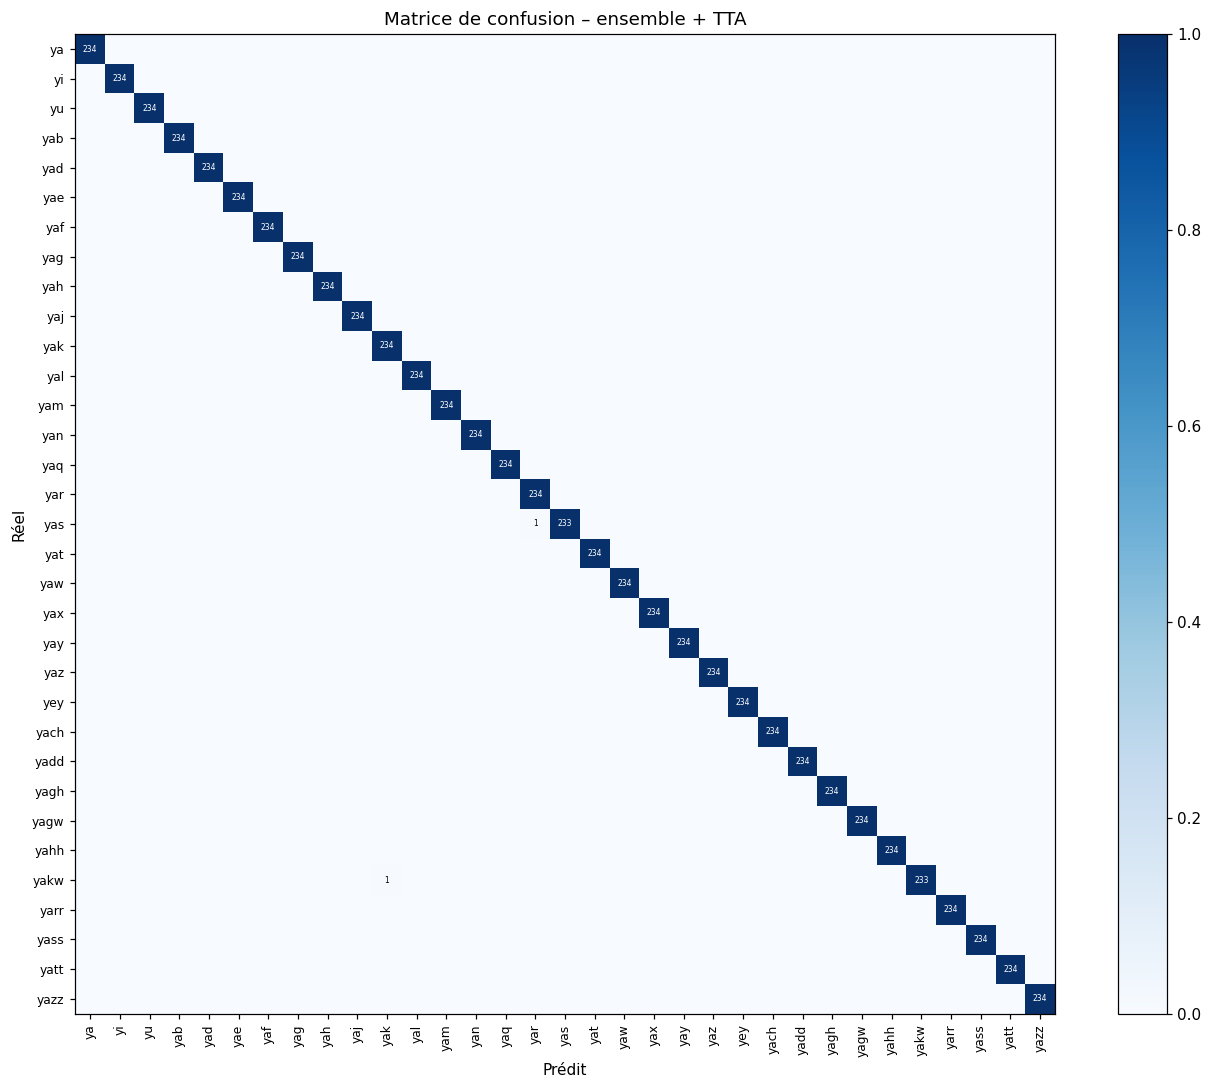

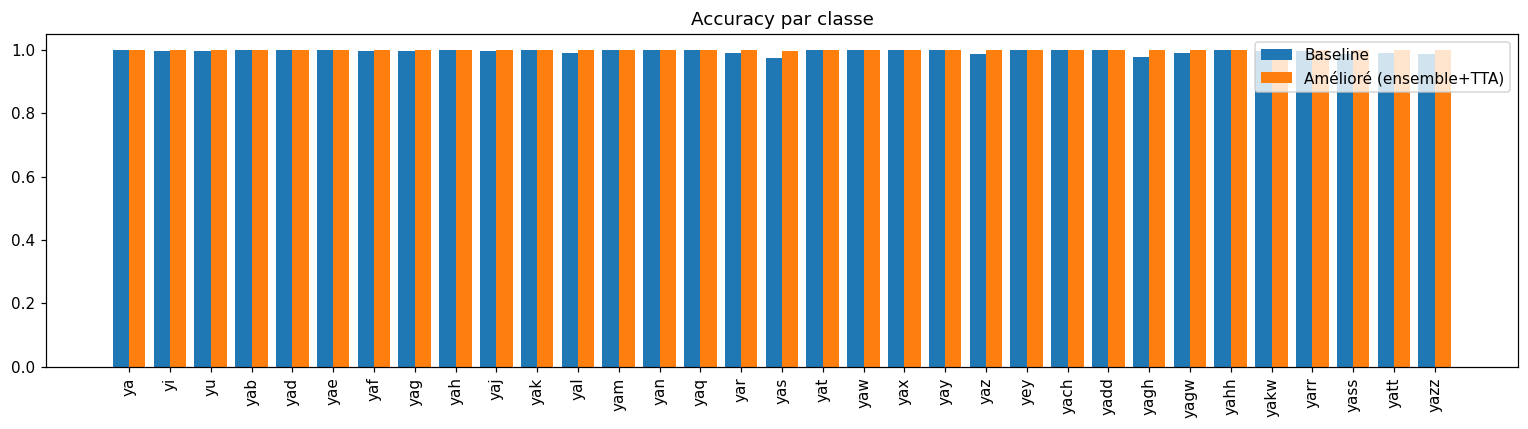

Erreurs corrigées : 33 | nouvelles erreurs : 0 | erreurs restantes : 2
Test de McNemar : chi2 = 31.03, p = 2.54e-08  (p < 0.05 => amélioration significative)


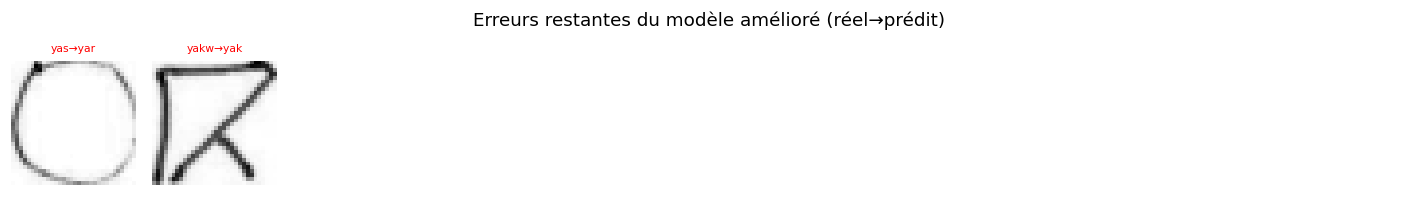

In [ ]:
def plot_cm(yt, yp, title, fname):
    cmx = confusion_matrix(yt, yp, labels=range(NUM_CLASSES))
    cmn = cmx / np.maximum(cmx.sum(1, keepdims=True), 1)
    plt.figure(figsize=(12, 10))
    plt.imshow(cmn, cmap='Blues'); plt.colorbar(fraction=0.046)
    plt.xticks(range(NUM_CLASSES), class_names, rotation=90, fontsize=8); plt.yticks(range(NUM_CLASSES), class_names, fontsize=8)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cmx[i, j] > 0:
                plt.text(j, i, cmx[i, j], ha='center', va='center', fontsize=5, color='white' if cmn[i, j] > .5 else 'black')
    plt.xlabel('Prédit'); plt.ylabel('Réel'); plt.title(title); plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/{fname}'); plt.show()
    return cmx

cm_f = plot_cm(yt_f, yp_f, 'Matrice de confusion – ensemble + TTA', 'confusion_matrix_final.png')

acc_b = np.array([(base_pred[base_true == k] == k).mean() for k in range(NUM_CLASSES)])
acc_f = np.array([(yp_f[yt_f == k] == k).mean() for k in range(NUM_CLASSES)])
x = np.arange(NUM_CLASSES)
plt.figure(figsize=(14, 4))
plt.bar(x - 0.2, acc_b, 0.4, label='Baseline'); plt.bar(x + 0.2, acc_f, 0.4, label='Amélioré (ensemble+TTA)')
plt.xticks(x, class_names, rotation=90); plt.ylim(0, 1.05); plt.legend(); plt.title('Accuracy par classe')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/per_class_comparison.png'); plt.show()

fixed  = int(np.sum((base_pred != yt_f) & (yp_f == yt_f)))     # erreurs corrigées
broken = int(np.sum((base_pred == yt_f) & (yp_f != yt_f)))     # nouvelles erreurs
print(f'Erreurs corrigées : {fixed} | nouvelles erreurs : {broken} | erreurs restantes : {int((yp_f != yt_f).sum())}')
if fixed + broken > 0:
    from scipy.stats import chi2
    stat = (abs(fixed - broken) - 1) ** 2 / (fixed + broken)
    print(f'Test de McNemar : chi2 = {stat:.2f}, p = {chi2.sf(stat, 1):.4g}  (p < 0.05 => amélioration significative)')

wrong_f = np.where(yp_f != yt_f)[0]
if len(wrong_f):
    ids = wrong_f[:30]
    fig, axs = plt.subplots(int(np.ceil(len(ids) / 10)), 10, figsize=(13, 1.8 * int(np.ceil(len(ids) / 10))))
    for ax in np.array(axs).ravel(): ax.axis('off')
    for ax, i in zip(np.array(axs).ravel(), ids):
        ax.imshow(denorm(test_X[i].numpy()), cmap='gray'); ax.set_title(f'{class_names[yt_f[i]]}→{class_names[yp_f[i]]}', fontsize=7, color='red')
    plt.suptitle('Erreurs restantes du modèle amélioré (réel→prédit)'); plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/errors_final.png'); plt.show()

### 12.4 Interprétabilité : Grad-CAM

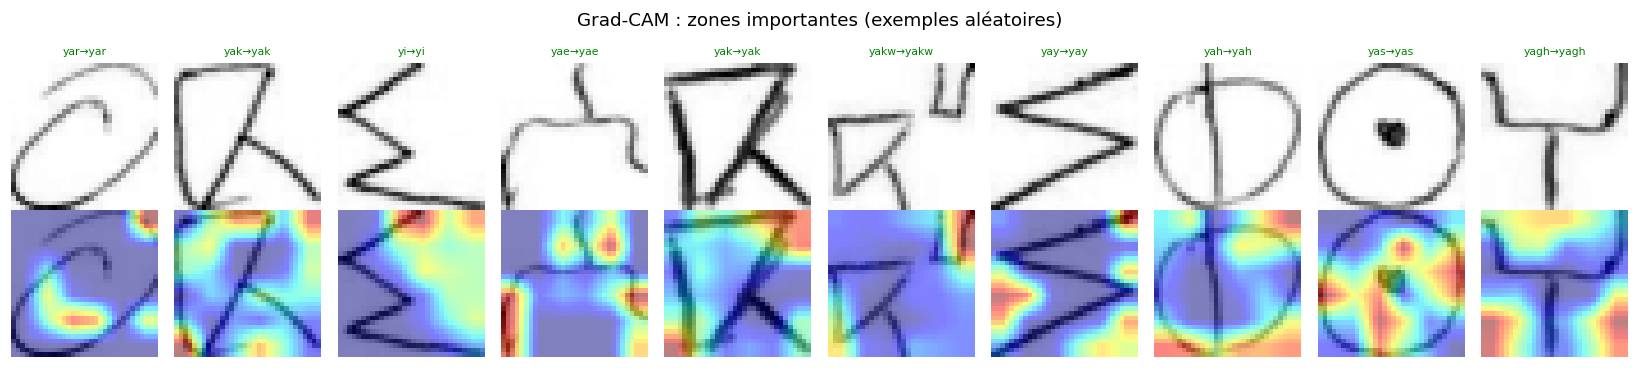

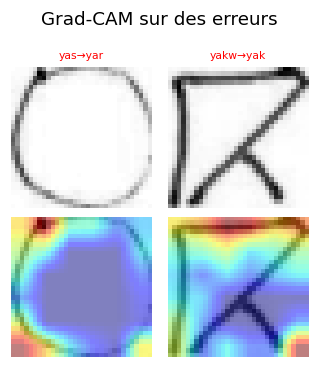

In [ ]:
def grad_cam(model, x, target=None):
    model.eval(); model.zero_grad()
    x = x.to(DEVICE)
    out, maps = model(x, return_maps=True)
    a = maps['S4']; a.retain_grad()
    t = out.argmax(1) if target is None else target
    out.gather(1, t.view(-1, 1)).sum().backward()
    w = a.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
    cam = cam - cam.amin(dim=(2, 3), keepdim=True)
    cam = cam / (cam.amax(dim=(2, 3), keepdim=True) + 1e-8)
    model.zero_grad()
    return cam.detach().cpu().numpy()[:, 0], out.argmax(1).cpu().numpy()

def show_gradcam(ids, title, fname):
    cams, preds = grad_cam(final_models[0], test_X[ids])
    n = len(ids)
    fig, axs = plt.subplots(2, n, figsize=(1.5 * n, 3.4))
    for k, i in enumerate(ids):
        img = denorm(test_X[i].numpy())
        axs[0, k].imshow(img, cmap='gray'); axs[0, k].axis('off')
        axs[0, k].set_title(f'{class_names[yt_f[i]]}→{class_names[preds[k]]}', fontsize=7,
                            color='green' if preds[k] == yt_f[i] else 'red')
        axs[1, k].imshow(img, cmap='gray'); axs[1, k].imshow(cams[k], cmap='jet', alpha=0.5); axs[1, k].axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/{fname}'); plt.show()

show_gradcam(list(rng.choice(len(yt_f), 10, replace=False)), 'Grad-CAM : zones importantes (exemples aléatoires)', 'gradcam_random.png')
if len(wrong_f): show_gradcam(list(wrong_f[:10]), 'Grad-CAM sur des erreurs', 'gradcam_errors.png')

In [ ]:
print('=' * 60)
print('RÉSUMÉ DES AMÉLIORATIONS')
print(f'Configuration retenue : {best_name}')
print(f'Baseline         : {final_df.iloc[0]["Test acc"]:.4f}')
print(f'Ensemble + TTA   : {final_df.iloc[-1]["Test acc"]:.4f}  (macro-F1 {final_df.iloc[-1]["Macro-F1"]:.4f})')
print(f'Gain total       : {final_df.iloc[-1]["Test acc"] - final_df.iloc[0]["Test acc"]:+.4f}')
print('=' * 60)

RÉSUMÉ DES AMÉLIORATIONS
Configuration retenue : 10 Tout combiné + LeNet5Plus
Baseline         : 0.9955
Ensemble + TTA   : 0.9997  (macro-F1 0.9997)
Gain total       : +0.0042


## 13. Résumé final (à recopier dans l'article IMRAD)

In [ ]:
print('=' * 55)
print(f'Optimiseur : {OPTIMIZER} | activation : {ACTIVATION} | epochs : {len(history["train_loss"])} | batch : {BATCH_SIZE}')
print(f'Paramètres : {count_params(model)}')
print(f'Train acc  : {history["train_acc"][-1]:.4f} | Val acc (best) : {history["best_val_acc"]:.4f}')
print(f'Test acc   : {test_acc:.4f} | Top-3 : {top3:.4f} | Macro-F1 : {f1:.4f}')
print(f'Images enregistrées dans : {os.path.abspath(OUT_DIR)}')
print('=' * 55)

Optimiseur : adam | activation : tanh | epochs : 29 | batch : 128
Paramètres : 63661
Train acc  : 0.9999 | Val acc (best) : 0.9974
Test acc   : 0.9955 | Top-3 : 0.9991 | Macro-F1 : 0.9955
Images enregistrées dans : /home/gotrinx/Desktop/tp/outputs
